# Edge-Enhanced Vision Transformer Framework — Reproduction Notebook

**Paper:** Edge-Enhanced Vision Transformer Framework for Accurate AI-Generated Image Detection  
**ArXiv:** https://arxiv.org/abs/2508.17877 (v1, 25 Aug 2025)  
**Authors:** Dabbrata Das, Mahshar Yahan, Md Tareq Zaman, Md Rishadul Bayesh

---

## Data source (no Kaggle needed)

Dataset loaded from the HuggingFace Hub: **`dragonintelligence/CIFAKE-image-dataset`**  
- Mirror of the original CIFAKE (Bird & Lotfi 2024, reference [4] of the paper)
- 120,000 images: train 100K + test 20K; label FAKE/REAL; images 32x32 px
- Loaded via `load_dataset()`, no Kaggle account required

## Code reused from the dima806 notebook

| Part | From dima806 | Change |
|---|---|---|
| Import libraries, PIL setup | Reused | Added cv2, removed mlflow/imblearn |
| ViTImageProcessor + Normalize | Reused | Changed model_str |
| `train_transforms`/`val_transforms` | Adapted | Removed RandomRotation+Sharpness, kept HorizontalFlip |
| `collate_fn` | Reused | Unchanged |
| `compute_metrics` | Adapted | Added F1/precision/recall |
| Trainer structure | Adapted | Hyperparameters set as in the paper |
| `plot_confusion_matrix` | Reused | Unchanged |
| `classification_report` | Reused | Unchanged |
| Data loading (Kaggle glob) | Replaced | load_dataset HuggingFace + 4K+4K sample |
| EBP module | Custom | Section 3.2.2, Eq.3-10 |
| Valley threshold | Custom | Algorithm 1 |
| Two-stage fusion | Custom | Algorithm 3 |

## Target (Table 6 — CIFAKE)
Fine-Tuned ViT + EBP: **Accuracy 97.75%, F1 97.77%, Precision 96.89%, Recall 98.67%, mIoU 95.60%**


In [1]:
# ============================================================
# CELL 1: INSTALL DEPENDENCIES
# ============================================================
!pip install -q \
    transformers==4.44.2 \
    datasets==2.21.0 \
    accelerate==0.33.0 \
    evaluate==0.4.3 \
    scikit-learn \
    tqdm pillow

print("Done. Now go to the menu: Runtime > Restart session")
print("After restarting, skip Cell 1 and run from Cell 2.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 67.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 527.3/527.3 kB 23.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 315.1/315.1 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.6/177.6 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 28.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 42.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 71.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-contrib-python 4.13.0.9

In [2]:
# ============================================================
# CELL 2: IMPORTS & GLOBAL SEED
# ============================================================
# Adapted from dima806 notebook imports section

import warnings

warnings.filterwarnings("ignore")

import os, gc, random, itertools
import numpy as np
import pandas as pd
# cv2: use the OpenCV version already available in Colab (4.13, compatible with NumPy 2.x)
try:
    import cv2
    print(f"cv2 version: {cv2.__version__}")
except ImportError:
    !pip install -q opencv-python-headless
    import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
from tqdm.auto import tqdm

# From dima806: allow truncated images
ImageFile.LOAD_TRUNCATED_IMAGES = True

from sklearn.metrics import (
    accuracy_score, confusion_matrix,
    classification_report, f1_score,
    precision_recall_fscore_support, jaccard_score,
)
from sklearn.model_selection import train_test_split

import torch
from torch.utils.data import Dataset as TorchDataset

from datasets import load_dataset
import evaluate
from transformers import (
    TrainingArguments, Trainer,
    ViTImageProcessor, ViTForImageClassification,
)
from torchvision.transforms import (
    Compose, Normalize, RandomHorizontalFlip, Resize, ToTensor,
)

# Global seed  [NOT STATED IN PAPER] -- standard convention
SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}  |  Seed: {SEED}")

# ------------------------------------------------------------
# Mount Drive and load the thesis utility module
# ------------------------------------------------------------
# `thesis_utils.py` must be uploaded to
#   /content/drive/MyDrive/luanvan_thac_si/thesis_utils.py
# before running this notebook.
from google.colab import drive
drive.mount('/content/drive')

import sys
THESIS_UTILS_DIR = '/content/drive/MyDrive/luanvan_thac_si'
if THESIS_UTILS_DIR not in sys.path:
    sys.path.append(THESIS_UTILS_DIR)

from thesis_utils import *
from thesis_explain import *
setup_thesis_style()


cv2 version: 4.13.0
Device: cuda  |  Seed: 42
Mounted at /content/drive
[OK] Thesis matplotlib style activated (serif, savefig 300 dpi).


In [3]:
# ============================================================
# CELL 3: GLOBAL CONFIGURATION
# All hyperparameters in one place -- never hardcode elsewhere
# Source: Section 4.2 + Tables 6, 8, 9 of paper arXiv:2508.17877
# ============================================================

CONFIG = {
    # Model (Section 3.2.1)
    'model_name'     : 'google/vit-base-patch16-224-in21k',
    'img_size'       : 224,
    'num_classes'    : 2,

    # Fine-Tuning (Section 4.2)
    'batch_size'     : 32,           # Paper: "batch size of 32"
    'num_epochs'     : 5,            # Paper: "5 training epochs"
    'lr'             : 1e-5,         # Paper: "learning rate of 1e-5"
    'weight_decay'   : 0.05,         # Paper: "weight decay of 0.05"
    'fp16'           : True,         # Paper: "FP16 mixed-precision"
    'best_metric'    : 'f1',         # Paper: "F1-score used as primary metric"

    # Edge-Based Processing (Section 3.2.2 + Tables 8-9)
    'gaussian_ksize' : 3,            # Table 9: 3x3 kernel optimal
    'gaussian_sigma' : 0,
    'canny_low'      : 100,          # [NOT STATED IN PAPER] OpenCV default
    'canny_high'     : 200,          # [NOT STATED IN PAPER] OpenCV default
    'eps'            : 1e-6,         # Eq.10: avoid div-by-zero
    'hist_bins'      : 50,           # Algorithm 1, line 7

    # Dataset (Section 4.1)
    'hf_dataset_id'  : 'dragonintelligence/CIFAKE-image-dataset',
    'n_per_class'    : 4000,         # Paper: "4,000 real and 4,000 synthetic"
    'train_ratio'    : 0.70,         # [NOT STATED IN PAPER]
    'val_ratio'      : 0.15,
    'test_ratio'     : 0.15,

    # Paths
    'ckpt_dir'       : '/content/checkpoints',
    'output_dir'     : '/content/outputs',

    # Paper targets for comparison (Table 6)
    'paper_accuracy' : 97.75,
    'paper_f1'       : 97.77,
    'paper_precision': 96.89,
    'paper_recall'   : 98.67,
    'paper_miou'     : 95.60,
    'tolerance'      : 1.5,

    # Reproducibility / multi-seed (advisor requirement)
    'seed'           : 42,            # canonical seed -> best_vit + headline
    'multiseed_seeds': [42, 1, 2, 3, 4],  # [NOT STATED IN PAPER] -- 5 seeds, mean +/- std
    'drive_backup'   : '/content/drive/MyDrive/luanvan_thac_si',
}

for d in [CONFIG['ckpt_dir'], CONFIG['output_dir']]:
    os.makedirs(d, exist_ok=True)
print("CONFIG loaded.")

CONFIG loaded.


In [4]:
# ============================================================
# CELL 4: LOAD CIFAKE FROM HUGGINGFACE  (no Kaggle API needed)
# ============================================================
# REPLACES dima806's glob('/kaggle/input/cifake-real-and-ai-generated-synthetic-images/*/*/*.*')
#
# Source: dragonintelligence/CIFAKE-image-dataset
#   -- Mirror of birdy654/cifake-real-and-ai-generated-synthetic-images (Kaggle)
#   -- Same data as paper reference [4] (Bird & Lotfi 2024)
#
# Dataset structure:
#   raw_ds['train'] : 100,000 images (50K FAKE + 50K REAL)
#   raw_ds['test']  :  20,000 images (10K FAKE + 10K REAL)
#   columns: 'image' (PIL 32x32 RGB), 'label' (ClassLabel: FAKE=0, REAL=1)

print("Loading CIFAKE from HuggingFace Hub...")
raw_ds = load_dataset(CONFIG['hf_dataset_id'])
print(f"  train: {len(raw_ds['train'])} images")
print(f"  test : {len(raw_ds['test'])}  images")

# Get label mapping from dataset features
label_feature = raw_ds['train'].features['label']
print(f"  Labels: {label_feature.names}")
id2label = {i: n for i, n in enumerate(label_feature.names)}
label2id = {n: i for i, n in id2label.items()}
FAKE_ID  = label2id['FAKE']   # typically 0
REAL_ID  = label2id['REAL']   # typically 1
CONFIG['class_names'] = label_feature.names
print(f"  FAKE_ID={FAKE_ID}, REAL_ID={REAL_ID}")

Loading CIFAKE from HuggingFace Hub...


Generating train split:   0%|          | 0/100000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/20000 [00:00<?, ? examples/s]

  train: 100000 images
  test : 20000  images
  Labels: ['FAKE', 'REAL']
  FAKE_ID=0, REAL_ID=1


In [5]:
# ============================================================
# CELL 5: BUILD 4K+4K SUBSET  (Section 4.1, paper)
# ============================================================
# Replaces dima806's RandomOverSampler + 60/40 split on 120K images.
#
# Strategy (adapted from dima806's concept of pooling all images):
#   1. Pool train + test splits -> separate by class
#   2. Sample n_per_class per class (fixed SEED)
#   3. Stratified 70/15/15 split -> train/val/test
#
# Paper (Section 4.1): "we selected a balanced subset containing
#   4,000 real and 4,000 synthetic images"

# -- Pool all PIL Images by class --
pool = {FAKE_ID: [], REAL_ID: []}
for split_name in ['train', 'test']:
    for item in tqdm(raw_ds[split_name], desc=f'Indexing {split_name}', leave=False):
        pool[item['label']].append(item['image'])

print(f"Pooled: FAKE={len(pool[FAKE_ID])}, REAL={len(pool[REAL_ID])}")

# -- Reproducible sampling --
rng = np.random.default_rng(SEED)
n   = CONFIG['n_per_class']

fake_idx = rng.choice(len(pool[FAKE_ID]), size=n, replace=False)
real_idx = rng.choice(len(pool[REAL_ID]), size=n, replace=False)

all_images = [pool[FAKE_ID][i] for i in fake_idx] + \
             [pool[REAL_ID][i] for i in real_idx]
all_labels = [FAKE_ID]*n + [REAL_ID]*n

print(f"Subset: {len(all_images)} images  "
      f"(FAKE={all_labels.count(FAKE_ID)}, REAL={all_labels.count(REAL_ID)})")

del pool; gc.collect()  # free 120K PIL Images

# -- Stratified 70/15/15 split [NOT STATED IN PAPER] --
imgs_trainval, imgs_test, lbl_trainval, lbl_test = train_test_split(
    all_images, all_labels,
    test_size=CONFIG['test_ratio'], stratify=all_labels, random_state=SEED)

val_frac = CONFIG['val_ratio'] / (CONFIG['train_ratio'] + CONFIG['val_ratio'])
imgs_train, imgs_val, lbl_train, lbl_val = train_test_split(
    imgs_trainval, lbl_trainval,
    test_size=val_frac, stratify=lbl_trainval, random_state=SEED)

print(f"Split -> train:{len(imgs_train)}  val:{len(imgs_val)}  test:{len(imgs_test)}")

Indexing train:   0%|          | 0/100000 [00:00<?, ?it/s]

Indexing test:   0%|          | 0/20000 [00:00<?, ?it/s]

Pooled: FAKE=60000, REAL=60000
Subset: 8000 images  (FAKE=4000, REAL=4000)
Split -> train:5600  val:1200  test:1200


In [6]:
# ============================================================
# CELL 6: IMAGE PROCESSOR + TRANSFORMS
# ============================================================
# Reused from dima806 notebook structure.
# Changes vs dima806:
#   model_str -> google/vit-base-patch16-224-in21k (not dima806 pretrained)
#   augmentation -> RandomHorizontalFlip ONLY (paper Section 4.1)
#     dima806 had RandomRotation(90) + RandomAdjustSharpness(2) -- NOT in paper

processor  = ViTImageProcessor.from_pretrained(CONFIG['model_name'])
image_mean = processor.image_mean
image_std  = processor.image_std
size       = processor.size["height"]  # 224
normalize  = Normalize(mean=image_mean, std=image_std)

print(f"Processor: resize to {size}x{size}")

# Paper Section 4.1: "horizontal flipping for data augmentation during training"
_train_transforms = Compose([
    Resize((size, size)),
    RandomHorizontalFlip(),   # Only augmentation stated in paper
    ToTensor(),
    normalize,
])

_val_transforms = Compose([
    Resize((size, size)),
    ToTensor(),
    normalize,
])


class CIFAKEDataset(TorchDataset):
    """PyTorch Dataset wrapping PIL Image lists. (Section 4.1, paper)"""
    def __init__(self, images, labels, transform):
        self.images    = images
        self.labels    = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx].convert('RGB')
        return {
            'pixel_values': self.transform(img),
            'labels'      : int(self.labels[idx]),
        }


# collate_fn: reused directly from dima806 notebook
def collate_fn(examples):
    pixel_values = torch.stack([e['pixel_values'] for e in examples])
    labels       = torch.tensor([e['labels'] for e in examples], dtype=torch.long)
    return {'pixel_values': pixel_values, 'labels': labels}


train_ds = CIFAKEDataset(imgs_train, lbl_train, _train_transforms)
val_ds   = CIFAKEDataset(imgs_val,   lbl_val,   _val_transforms)
test_ds  = CIFAKEDataset(imgs_test,  lbl_test,  _val_transforms)

print(f"Datasets: train={len(train_ds)}  val={len(val_ds)}  test={len(test_ds)}")
s = train_ds[0]
print(f"Sample: shape={tuple(s['pixel_values'].shape)}  label={s['labels']}({id2label[s['labels']]})")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Processor: resize to 224x224
Datasets: train=5600  val=1200  test=1200
Sample: shape=(3, 224, 224)  label=0(FAKE)


In [7]:
# ============================================================
# CELL 7: MODEL + COMPUTE METRICS
# ============================================================
# Model: reused from dima806 structure.
# compute_metrics: adapted from dima806 -- added F1/precision/recall.
#   dima806: only accuracy.
#   Paper Section 4.2: "F1-score was used as the primary metric"

def build_model():
    """Fresh ViT-Base/16 from in21k weights. Called once per seed by train_vit().
    Section 3.2.1, paper. Re-instantiating per seed guarantees each multi-seed
    run starts from the same pretrained init with a different fine-tune seed."""
    m = ViTForImageClassification.from_pretrained(
        CONFIG['model_name'],
        num_labels=CONFIG['num_classes'],
        id2label=id2label,
        label2id=label2id,
    )
    return m.to(DEVICE)

_probe = build_model()
print(f"ViT-Base/16: {sum(p.numel() for p in _probe.parameters())/1e6:.1f}M params  (paper: 86M)")
del _probe  # free; train_vit() builds its own

accuracy_metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    """Accuracy + F1 + precision + recall (adapted from dima806)."""
    logits, labels = eval_pred
    preds = logits.argmax(axis=-1)
    acc   = accuracy_metric.compute(predictions=preds, references=labels)['accuracy']
    p, r, f1, _ = precision_recall_fscore_support(
        labels, preds, average='binary', pos_label=FAKE_ID)   # advisor: positive class = FAKE
    return {'accuracy': acc, 'f1': f1, 'precision': p, 'recall': r}

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


ViT-Base/16: 85.8M params  (paper: 86M)


In [8]:
# ============================================================
# CELL 8: train_vit(seed) -- ONE training function = one source of truth
# ============================================================
# Refactor of the old Cell 8/9. Every model in this thesis (headline
# seed-42 -> best_vit, AND every seed of the multi-seed table) is produced
# by THIS function, so Section 5.1.2 (single seed 42) and Section 5.1.5
# (multi-seed) can never disagree again.
#
# Protocol (advisor, Section 5.1.5): the data subset + 70/15/15 split are
# fixed at data-seed 42 (built once in Cell 5). train_vit only changes the
# FINE-TUNE seed (weight-init + dataloader shuffle order). This isolates
# model-init variance, not data-split variance.
#
# All TrainingArguments values are unchanged from the paper (Section 4.2):
#   lr=1e-5, weight_decay=0.05, batch=32, 5 epochs, FP16, best-model-by-F1.

import os
import numpy as np
from scipy.special import softmax


def train_vit(seed, save_dir=None, verbose=True):
    """Fine-tune ViT with a given fine-tune seed; return trainer + test metrics.

    Parameters
    ----------
    seed : int
        Fine-tune seed (weight init + shuffle). Data split stays fixed.
    save_dir : str or None
        If given, the best checkpoint is exported here (used for best_vit).
    verbose : bool
        Print per-run summary. Set False inside the multi-seed loop.

    Returns
    -------
    dict with keys: trainer, outputs, y_true, y_pred, probs, metrics, result.
    """
    set_seed(seed)
    model = build_model()

    args = TrainingArguments(
        output_dir                  = os.path.join(CONFIG['ckpt_dir'], f'run_seed{seed}'),
        logging_dir                 = './logs',
        per_device_train_batch_size = CONFIG['batch_size'],
        per_device_eval_batch_size  = CONFIG['batch_size'],
        num_train_epochs            = CONFIG['num_epochs'],
        learning_rate               = CONFIG['lr'],
        weight_decay                = CONFIG['weight_decay'],
        fp16                        = CONFIG['fp16'] and torch.cuda.is_available(),
        eval_strategy               = 'epoch',
        save_strategy               = 'epoch',
        logging_strategy            = 'epoch',
        load_best_model_at_end      = True,
        metric_for_best_model       = CONFIG['best_metric'],   # 'f1' (paper)
        greater_is_better           = True,
        save_total_limit            = 2,
        remove_unused_columns       = False,
        report_to                   = 'none',
        seed                        = seed,                    # <-- the only thing that varies
    )

    trainer = Trainer(
        model           = model,
        args            = args,
        train_dataset   = train_ds,
        eval_dataset    = val_ds,
        data_collator   = collate_fn,
        compute_metrics = compute_metrics,
        tokenizer       = processor,
    )

    if verbose:
        pre = trainer.evaluate()
        print(f"  [seed {seed}] pre-train baseline: "
              f"acc={pre['eval_accuracy']*100:.2f}%  f1={pre['eval_f1']*100:.2f}%")

    result = trainer.train()
    if save_dir is not None:
        trainer.save_model(save_dir)

    out      = trainer.predict(test_ds)
    y_true   = np.asarray(out.label_ids)
    y_pred   = out.predictions.argmax(1)
    probs    = softmax(out.predictions.astype(np.float32), axis=1)
    pf       = probs[:, FAKE_ID]                       # P(FAKE) as score (FAKE positive)
    metrics  = format_metrics_dict(y_true=y_true, y_pred=y_pred,
                                   y_score=pf, pos_label=FAKE_ID)

    if verbose:
        print(f"  [seed {seed}] test: acc={metrics['Accuracy (%)']:.2f}%  "
              f"F1={metrics['F1-Score (%)']:.2f}%  "
              f"AUC-ROC={metrics.get('AUC-ROC (%)', float('nan')):.2f}%")

    return {'trainer': trainer, 'outputs': out, 'y_true': y_true,
            'y_pred': y_pred, 'probs': probs, 'metrics': metrics, 'result': result}


In [9]:
# ============================================================
# CELL 9: RUN SEED 42  ->  best_vit  (THIS is the "last training")
# ============================================================
# Produces the canonical checkpoint best_vit and the headline numbers.
# All downstream cells (EBP, 5 modes, error analysis, save) reuse the
# globals set here. The multi-seed section at the end reuses _run42 for
# the seed-42 row, so it never retrains seed 42.

best_vit_dir = os.path.join(CONFIG['ckpt_dir'], 'best_vit')

_run42 = train_vit(CONFIG['seed'], save_dir=best_vit_dir, verbose=True)

# Expose the globals the original downstream cells expect:
trainer            = _run42['trainer']     # used by Cell 10/12a and per-epoch table
outputs            = _run42['outputs']     # used by Cell 12a (ViT probs)
vit_true           = _run42['y_true']
vit_pred           = _run42['y_pred']
HEADLINE_METRICS   = _run42['metrics']     # canonical ViT-only metrics (positive=FAKE)
MS_SEED42_METRICS  = _run42['metrics']     # reused by the multi-seed section (no retrain)

print("\n" + "=" * 60)
print(" CANONICAL HEADLINE  (seed {}, positive class = FAKE)".format(CONFIG['seed']))
print("=" * 60)
print(f"  ViT-only Accuracy : {HEADLINE_METRICS['Accuracy (%)']:.2f}%")
print(f"  ViT-only F1       : {HEADLINE_METRICS['F1-Score (%)']:.2f}%")
print(f"  AUC-ROC           : {HEADLINE_METRICS.get('AUC-ROC (%)', float('nan')):.2f}%")
print("  -> paste these exact numbers into thesis Section 5.1.2 / Table 5.10 (B1).")
print("  NOTE: with FP16 on GPU, this seed may shift +/-~0.2pp across runtimes;")
print("        the notebook reports whatever it computes -- nothing is hardcoded.")
print("=" * 60)


Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  [seed 42] pre-train baseline: acc=48.42%  f1=54.85%


Epoch,Training Loss,Validation Loss,Model Preparation Time,Accuracy,F1,Precision,Recall
1,0.440500,0.190550,0.002600,0.941667,0.940273,0.963287,0.918333
2,0.148500,0.131052,0.002600,0.959167,0.959737,0.946515,0.973333
3,0.100100,0.120579,0.002600,0.964167,0.964725,0.949919,0.980000
4,0.076000,0.120332,0.002600,0.964167,0.963713,0.976068,0.951667
5,0.064300,0.109533,0.002600,0.965833,0.965862,0.965058,0.966667


  [seed 42] test: acc=95.83%  F1=95.81%  AUC-ROC=99.30%

 CANONICAL HEADLINE  (seed 42, positive class = FAKE)
  ViT-only Accuracy : 95.83%
  ViT-only F1       : 95.81%
  AUC-ROC           : 99.30%
  -> paste these exact numbers into thesis Section 5.1.2 / Table 5.10 (B1).
  NOTE: with FP16 on GPU, this seed may shift +/-~0.2pp across runtimes;
        the notebook reports whatever it computes -- nothing is hardcoded.


--- Fine-Tuned ViT (no EBP) ---
  Accuracy : 95.83%  (paper: 96.42%)
  F1-Score : 95.81%   (paper: 96.45%)
  Precision: 96.45%   (paper: 95.58%)
  Recall   : 95.17%   (paper: 97.33%)


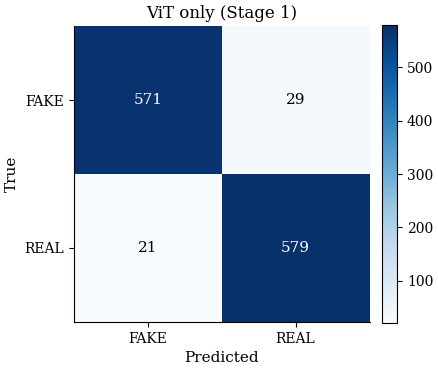

              precision    recall  f1-score   support

        FAKE     0.9645    0.9517    0.9581       600
        REAL     0.9523    0.9650    0.9586       600

    accuracy                         0.9583      1200
   macro avg     0.9584    0.9583    0.9583      1200
weighted avg     0.9584    0.9583    0.9583      1200



In [10]:
# ============================================================
# CELL 10: STAGE-1 EVALUATION (ViT only)
# ============================================================
# Evaluation pipeline reused directly from dima806 notebook:
#   trainer.predict() -> y_true/y_pred -> confusion_matrix -> classification_report

outputs     = trainer.predict(test_ds)
vit_true    = outputs.label_ids
vit_pred    = outputs.predictions.argmax(1)

vit_acc = accuracy_score(vit_true, vit_pred)
vit_p, vit_r, vit_f1, _ = precision_recall_fscore_support(
    vit_true, vit_pred, average='binary', pos_label=FAKE_ID)   # advisor: positive = FAKE

print(f"--- Fine-Tuned ViT (no EBP) ---")
print(f"  Accuracy : {vit_acc*100:.2f}%  (paper: 96.42%)")
print(f"  F1-Score : {vit_f1*100:.2f}%   (paper: 96.45%)")
print(f"  Precision: {vit_p*100:.2f}%   (paper: 95.58%)")
print(f"  Recall   : {vit_r*100:.2f}%   (paper: 97.33%)")

# Confusion matrix: imported from thesis_utils (replaces dima806 local def)

import os
os.makedirs(CONFIG['output_dir'], exist_ok=True)
plot_confusion_matrix(
    confusion_matrix(vit_true, vit_pred),
    CONFIG['class_names'], title='ViT only (Stage 1)',
    save_path=os.path.join(CONFIG['output_dir'], 'fig_cm_vit_stage1.png'),
)
print(classification_report(vit_true, vit_pred,
                            target_names=CONFIG['class_names'], digits=4))

Computing EBP scores on validation set (calibration)...


EBP:   0%|          | 0/1200 [00:00<?, ?it/s]

Median Real=0.033  Median Fake=0.034
Valley threshold T = 0.0339


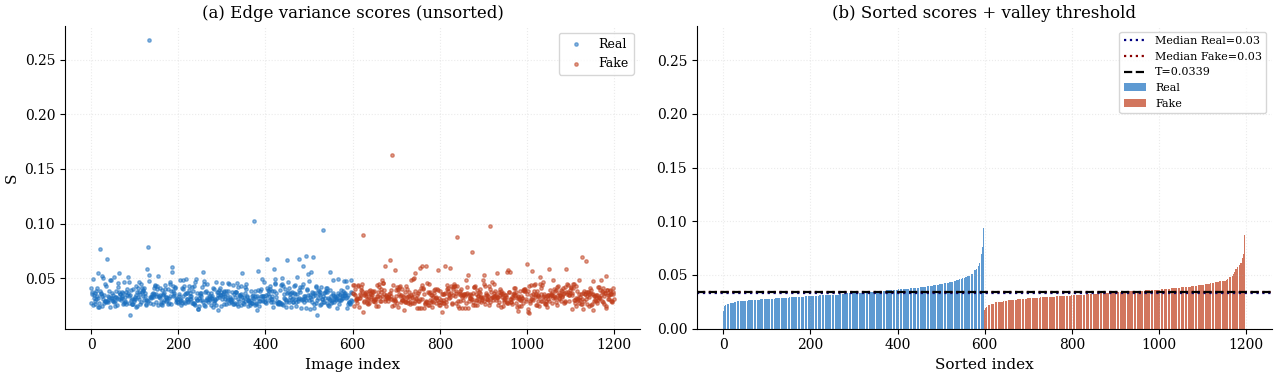

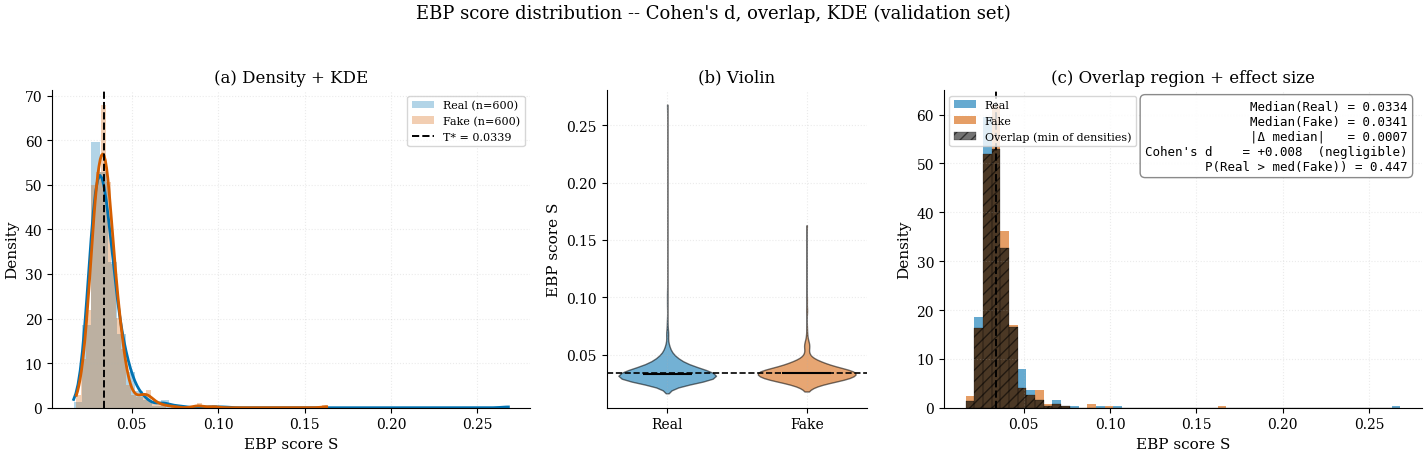

Case study indices: REAL = val[192], FAKE = val[883]


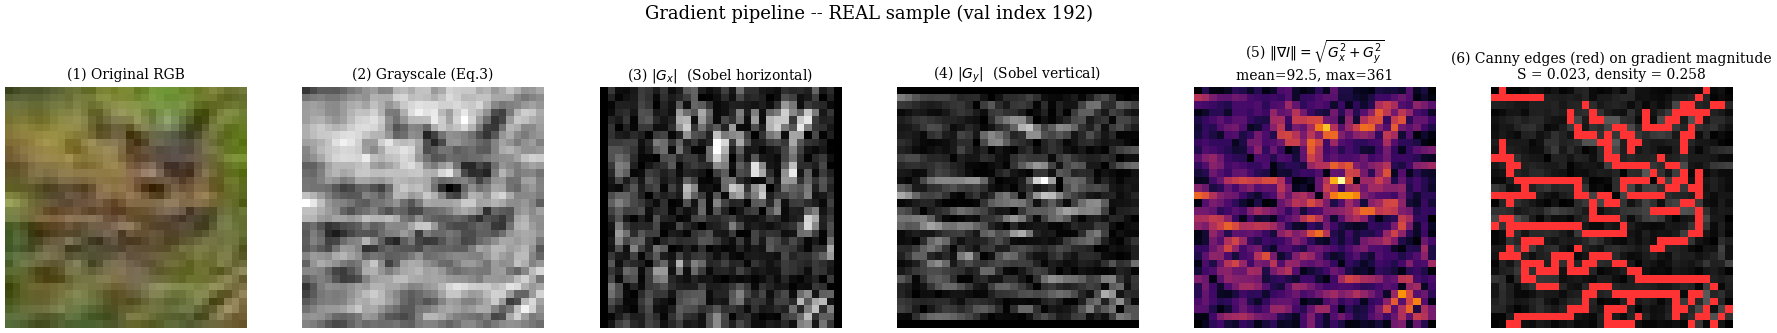

REAL: grad_mean=92.45, S=0.023, edge_density=0.258


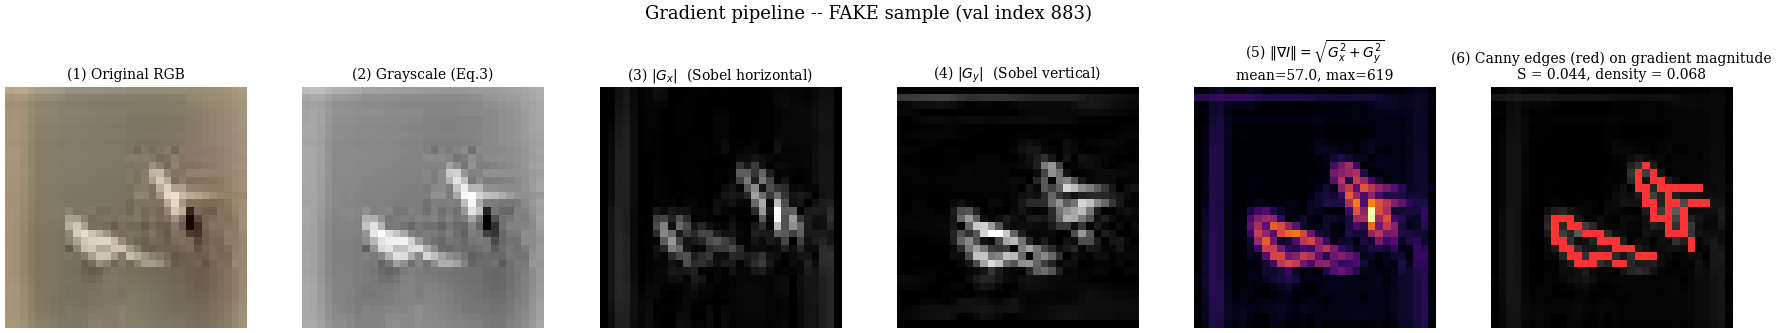

FAKE: grad_mean=57.01, S=0.044, edge_density=0.068


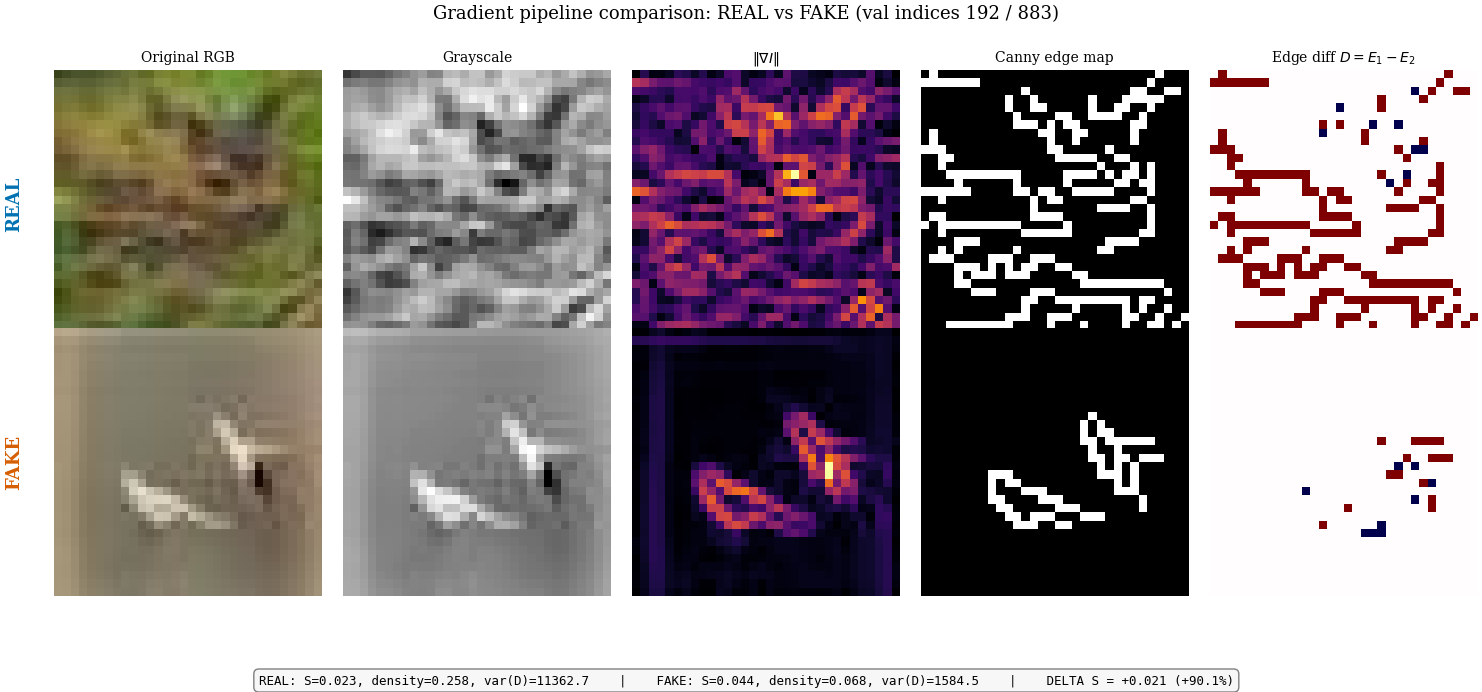


Gradient comparison table:
class  grad_mean  grad_std  edge_density  n_edges    var(D)  EBP score S
 REAL     92.455    57.828         0.258      264 11362.706        0.023
 FAKE     57.013    81.164         0.068       70  1584.486        0.044


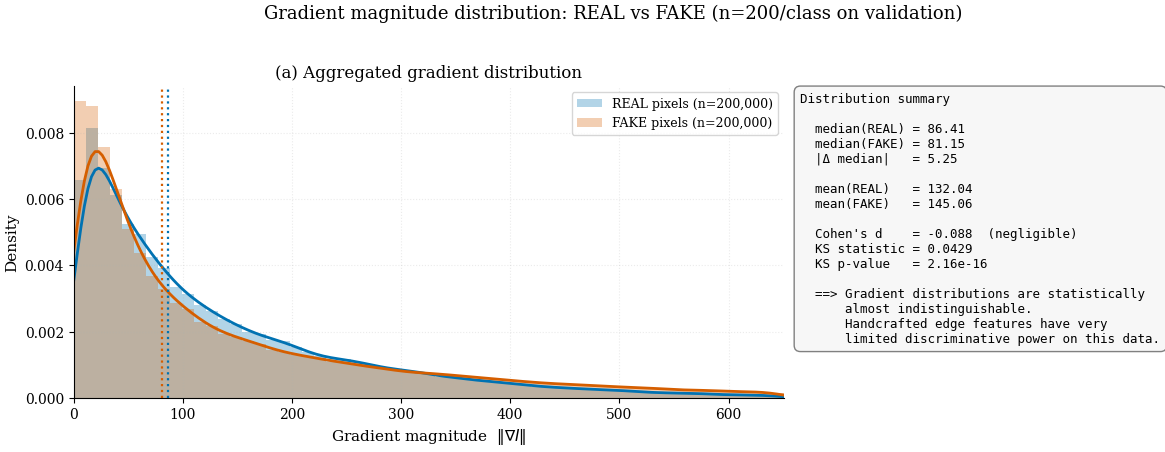


Gradient distribution summary:
  Cohen's d   = -0.088 (negligible)
  KS statistic = 0.0429
  KS p-value   = 2.16e-16


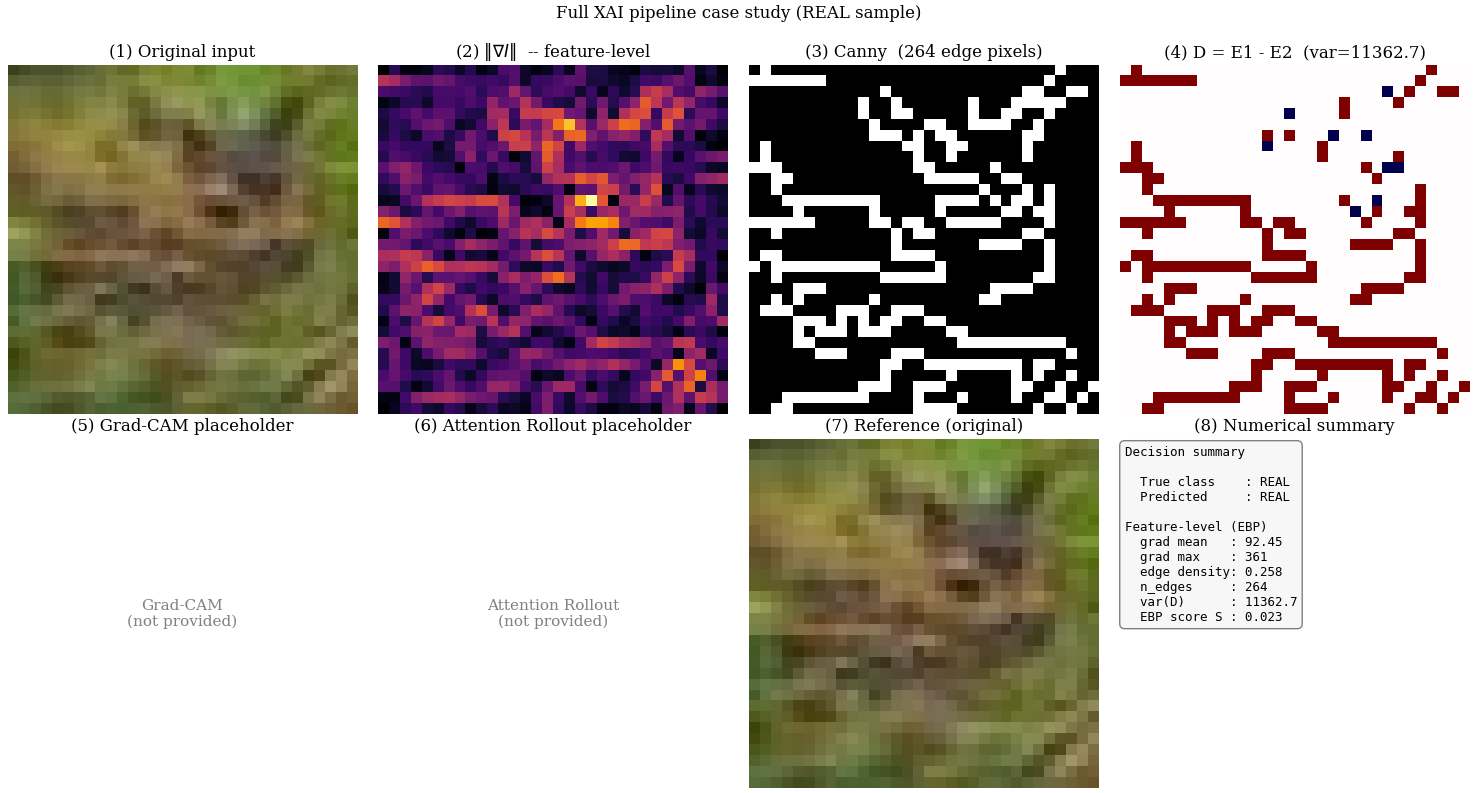


Full XAI pipeline (feature-level only for now):
  S = 0.023, n_edges = 264


In [11]:
# ============================================================
# CELL 11: EDGE-BASED PROCESSING MODULE  (Section 3.2.2, paper)
# ============================================================
# NOT in dima806 notebook -- implemented from paper equations.
#
# Eq.3  I_g = grayscale(RGB)
# Eq.4  I_b = GaussianBlur(I_g, 3x3)         [Table 9: 3x3 optimal]
# Eq.5  E1  = Canny(I_g, T_low, T_high)
# Eq.6  E2  = Canny(I_b, T_low, T_high)
# Eq.7  D   = E1 - E2
# Eq.9  sigma2_D = var(D)
# Eq.10 S   = N_edges / (sigma2_D + eps)
#
# Intuition: AI images -> smoother -> E1≈E2 -> small var -> LARGE S
#            Real images -> noisier -> E1≠E2 -> large var -> SMALL S

def compute_edge_score(pil_img, ksize=3, sigma=0.0,
                       canny_low=100, canny_high=200, eps=1e-6):
    img_np  = np.array(pil_img.convert('RGB'))
    gray    = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)      # Eq.3
    blurred = cv2.GaussianBlur(gray, (ksize, ksize), sigma) # Eq.4
    E1      = cv2.Canny(gray,    canny_low, canny_high)     # Eq.5
    E2      = cv2.Canny(blurred, canny_low, canny_high)     # Eq.6
    D       = E1.astype(np.int16) - E2.astype(np.int16)    # Eq.7
    var_D   = float(np.var(D))                              # Eq.9
    n_edges = int(np.count_nonzero(E1))
    return n_edges / (var_D + eps)                          # Eq.10


def compute_scores_batch(images):
    return np.array([
        compute_edge_score(
            img,
            ksize      = CONFIG['gaussian_ksize'],
            sigma      = CONFIG['gaussian_sigma'],
            canny_low  = CONFIG['canny_low'],
            canny_high = CONFIG['canny_high'],
            eps        = CONFIG['eps'],
        )
        for img in tqdm(images, desc='EBP', leave=False)
    ])


# Valley threshold (Algorithm 1, paper)
def compute_valley_threshold(scores_real, scores_fake, n_bins=50):
    if not len(scores_real) or not len(scores_fake):
        return None
    mR = float(np.median(scores_real))
    mF = float(np.median(scores_fake))
    all_s = np.concatenate([scores_real, scores_fake])
    counts, edges = np.histogram(all_s, bins=n_bins)
    centers = (edges[:-1] + edges[1:]) / 2.0
    lo, hi = min(mR, mF), max(mR, mF)
    mask = (centers >= lo) & (centers <= hi)
    if not mask.any():
        return (mR + mF) / 2.0
    return float(centers[mask][np.argmin(counts[mask])])


# Calibrate on VALIDATION set
print("Computing EBP scores on validation set (calibration)...")
val_scores = compute_scores_batch(imgs_val)
sr = val_scores[np.array(lbl_val) == REAL_ID]
sf = val_scores[np.array(lbl_val) == FAKE_ID]

T_star = compute_valley_threshold(sr, sf, CONFIG['hist_bins'])
print(f"Median Real={np.median(sr):.3f}  Median Fake={np.median(sf):.3f}")
print(f"Valley threshold T = {T_star:.4f}")

# Figure 2 reproduction
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(range(len(sr)), sr, s=6, alpha=0.5, label='Real', c='#1a6fbf')
axes[0].scatter(range(len(sr), len(sr)+len(sf)), sf, s=6, alpha=0.5, label='Fake', c='#bf3c1a')
axes[0].set(title='(a) Edge variance scores (unsorted)', xlabel='Image index', ylabel='S')
axes[0].legend()
axes[1].bar(range(len(sr)), np.sort(sr), color='#1a6fbf', alpha=0.7, label='Real')
axes[1].bar(range(len(sr), len(sr)+len(sf)), np.sort(sf), color='#bf3c1a', alpha=0.7, label='Fake')
axes[1].axhline(np.median(sr), ls=':', color='navy',   label=f'Median Real={np.median(sr):.2f}')
axes[1].axhline(np.median(sf), ls=':', color='darkred',label=f'Median Fake={np.median(sf):.2f}')
axes[1].axhline(T_star, ls='--', color='k', label=f'T={T_star:.4f}')
axes[1].set(title='(b) Sorted scores + valley threshold', xlabel='Sorted index')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['output_dir'], 'fig2_edge_scores_VAL.png'), dpi=150)
plt.show()
plot_ebp_distribution_detailed(
    scores_real=sr, scores_fake=sf,
    threshold=T_star,
    score_name='EBP score S',
    title='EBP score distribution -- Cohen\'s d, overlap, KDE '
          '(validation set)',
    save_path=os.path.join(CONFIG['output_dir'],
                           'fig_ebp_distribution_detailed.png'),
)

# ============================================================
# CELL 11 EXTENSION: Gradient image analysis (feature-level XAI)
# ============================================================
# Per advisor request: visualize Gradient Images from feature images.
# Bridges EBP (Edge-Based Processing) with model-level XAI (Grad-CAM,
# Attention Rollout in Notebook 03).
#
# Pipeline:
#   Input -> Grayscale -> Gaussian blur
#         -> Sobel Gx, Gy -> Gradient magnitude
#         -> Canny edges -> Edge difference D = E1 - E2 -> EBP score S
#
# Functions live in thesis_explain.py (already imported in Cell 2).

# ---- 11a. Pick one REAL and one FAKE for case study (deterministic) ----
lbl_arr = np.asarray(lbl_val)
real_indices = np.where(lbl_arr == REAL_ID)[0]
fake_indices = np.where(lbl_arr == FAKE_ID)[0]

case_rng = np.random.RandomState(CONFIG.get('seed', 42))
real_case_idx = int(case_rng.choice(real_indices))
fake_case_idx = int(case_rng.choice(fake_indices))

real_case = imgs_val[real_case_idx]
fake_case = imgs_val[fake_case_idx]
print(f'Case study indices: REAL = val[{real_case_idx}], '
      f'FAKE = val[{fake_case_idx}]')


# ---- 11b. 6-panel pipeline figure for the REAL sample ----
fig, stats_real_grad = show_gradient_panel(
    real_case,
    title=f'Gradient pipeline -- REAL sample (val index {real_case_idx})',
    save_path=os.path.join(CONFIG['output_dir'],
                           'fig_gradient_panel_real.png'),
)
print(f"REAL: grad_mean={stats_real_grad['grad_mean']:.2f}, "
      f"S={stats_real_grad['ebp_score']:.3f}, "
      f"edge_density={stats_real_grad['edge_density']:.3f}")


# ---- 11c. 6-panel pipeline figure for the FAKE sample ----
fig, stats_fake_grad = show_gradient_panel(
    fake_case,
    title=f'Gradient pipeline -- FAKE sample (val index {fake_case_idx})',
    save_path=os.path.join(CONFIG['output_dir'],
                           'fig_gradient_panel_fake.png'),
)
print(f"FAKE: grad_mean={stats_fake_grad['grad_mean']:.2f}, "
      f"S={stats_fake_grad['ebp_score']:.3f}, "
      f"edge_density={stats_fake_grad['edge_density']:.3f}")


# ---- 11d. Side-by-side REAL vs FAKE comparison ----
fig, gradient_cmp_df = show_gradient_comparison(
    real_case, fake_case,
    title='Gradient pipeline comparison: REAL vs FAKE '
          f'(val indices {real_case_idx} / {fake_case_idx})',
    save_path=os.path.join(CONFIG['output_dir'],
                           'fig_gradient_comparison.png'),
)
print('\nGradient comparison table:')
print(gradient_cmp_df.to_string(index=False,
                                 float_format=lambda x: f'{x:.3f}'))


# ---- 11e. Population-level gradient distribution + Cohen's d + KS test ----
# Random subset for runtime (~30-60s for 400 images on Colab T4)
n_per_class = 200
real_pool_idx = case_rng.choice(real_indices,
                                size=min(n_per_class, len(real_indices)),
                                replace=False)
fake_pool_idx = case_rng.choice(fake_indices,
                                size=min(n_per_class, len(fake_indices)),
                                replace=False)
real_pool = [imgs_val[i] for i in real_pool_idx]
fake_pool = [imgs_val[i] for i in fake_pool_idx]

fig, grad_dist_summary = plot_gradient_distribution(
    real_pool, fake_pool,
    sample_pixels_per_image=1000,
    seed=CONFIG.get('seed', 42),
    title=f'Gradient magnitude distribution: REAL vs FAKE '
          f'(n={n_per_class}/class on validation)',
    save_path=os.path.join(CONFIG['output_dir'],
                           'fig_gradient_distribution.png'),
)
print(f"\nGradient distribution summary:")
print(f"  Cohen's d   = {grad_dist_summary['cohens_d']:+.3f} "
      f"({grad_dist_summary['cohens_d_size']})")
if grad_dist_summary['ks_statistic'] is not None:
    print(f"  KS statistic = {grad_dist_summary['ks_statistic']:.4f}")
    print(f"  KS p-value   = {grad_dist_summary['ks_pvalue']:.2e}")


# ---- 11f. (OPTIONAL) Full XAI pipeline placeholder for Notebook 03 ----
# Run this now to produce the feature-level part; Grad-CAM and
# Attention Rollout panels will show placeholders until Notebook 03
# computes them. Replace gradcam=None / attention_rollout=None with
# actual heatmap arrays once available.
fig, xai_summary = show_full_xai_pipeline(
    real_case,
    true_label='REAL',
    predicted_label='REAL',
    vit_confidence=None,         # plug in vit_conf_val[real_case_idx] if computed earlier
    gradcam=None,                # to be filled in by Notebook 03
    attention_rollout=None,      # to be filled in by Notebook 03
    title='Full XAI pipeline case study (REAL sample)',
    save_path=os.path.join(CONFIG['output_dir'],
                           'fig_full_xai_pipeline_real.png'),
)
print(f"\nFull XAI pipeline (feature-level only for now):")
print(f"  S = {xai_summary['feature_level']['ebp_score']:.3f}, "
      f"n_edges = {xai_summary['feature_level']['n_edges']}")


# Cell 12: No-Leak Inference Pipeline

**Why we are replacing the original Cell 12.**

The original code identified misclassified test images using ground
truth labels and applied EBP only to those:

```python
misclassified = (final_pred != gt_labels)   # uses test ground truth
final_pred[misclassified] = ebp_pred[misclassified]
```

At real inference time we do not know which images ViT got wrong, so
this is a test-label leak (oracle correction). The 98.33% it reported
is not reproducible by a deployable system.

This replacement evaluates four no-leak inference modes:
- Mode 1: ViT only
- Mode 2: EBP only (threshold-based, calibrated on validation)
- Mode 3: Confidence-gated ViT + EBP (tau calibrated on validation)
- Mode 4: Logistic Regression fusion of ViT and EBP (trained on validation)

We also keep Mode 0 (the old leaked result) as a diagnostic record.

In [12]:
# ============================================================
# CELL 12a: ViT PROBABILITIES ON VAL + TEST (prerequisite)
# ============================================================
# We need softmax probabilities for:
#   - ViT confidence (max softmax) -> Mode 3 gating
#   - P(FAKE) as a fusion feature  -> Mode 4 LogReg
#   - AUC-ROC and PR-AUC reporting (advisor flagged these as missing)
#
# This cell runs trainer.predict on the validation set in addition to
# the test set predictions already produced by Cell 10. Validation-side
# probabilities are needed for any calibration step.

import numpy as np
from scipy.special import softmax

# --- EBP scores on TEST -- moved here from the old Cell 12 -----------
# The old Cell 12 (which we are replacing) computed `test_scores`.
# Since users will delete that cell, recompute the scores here so that
# every Mode below has the value it needs. `compute_scores_batch` and
# `imgs_test` were defined in the previous cells (11 and 5).
print('Computing EBP scores on test set...')
test_scores = compute_scores_batch(imgs_test)

# --- Test set (already predicted by Cell 10, just extract probs) ----
# `outputs.predictions` from Cell 10 has shape (N, 2): logits per class.
# If Cell 10 ran with FP16, predictions may be float16 -- cast to float32
# before softmax to avoid numerical instability.
vit_logits_test  = outputs.predictions.astype(np.float32)
vit_probs_test   = softmax(vit_logits_test, axis=1)          # (N, 2)
vit_pf_test      = vit_probs_test[:, FAKE_ID]                # P(FAKE)
vit_conf_test    = vit_probs_test.max(axis=1)                # confidence
gt_test          = np.asarray(vit_true)                       # alias

# --- Validation set (new prediction) --------------------------------
outputs_val      = trainer.predict(val_ds)
vit_logits_val   = outputs_val.predictions.astype(np.float32)
vit_probs_val    = softmax(vit_logits_val, axis=1)
vit_pf_val       = vit_probs_val[:, FAKE_ID]
vit_conf_val     = vit_probs_val.max(axis=1)
vit_pred_val     = vit_logits_val.argmax(axis=1)
gt_val           = np.asarray(outputs_val.label_ids)

print(f'ViT confidence on test : min={vit_conf_test.min():.3f}, '
      f'mean={vit_conf_test.mean():.3f}, max={vit_conf_test.max():.3f}')
print(f'ViT confidence on val  : min={vit_conf_val.min():.3f}, '
      f'mean={vit_conf_val.mean():.3f}, max={vit_conf_val.max():.3f}')

# `test_scores` and `val_scores` already exist from Cells 11 and 12.
# Sanity check shapes before we go further.
assert len(test_scores) == len(gt_test), 'test_scores length mismatch'
assert len(val_scores)  == len(gt_val),  'val_scores length mismatch'

Computing EBP scores on test set...


EBP:   0%|          | 0/1200 [00:00<?, ?it/s]

ViT confidence on test : min=0.504, mean=0.968, max=0.986
ViT confidence on val  : min=0.504, mean=0.967, max=0.986


Real -> Fake (cell [0,1]) : 21 images
Fake -> Real (cell [1,0]) : 29 images
Total errors = 50 / 1200  ->  ViT-only acc = 95.83%

===== Real -> Fake: showing 8/21 images =====


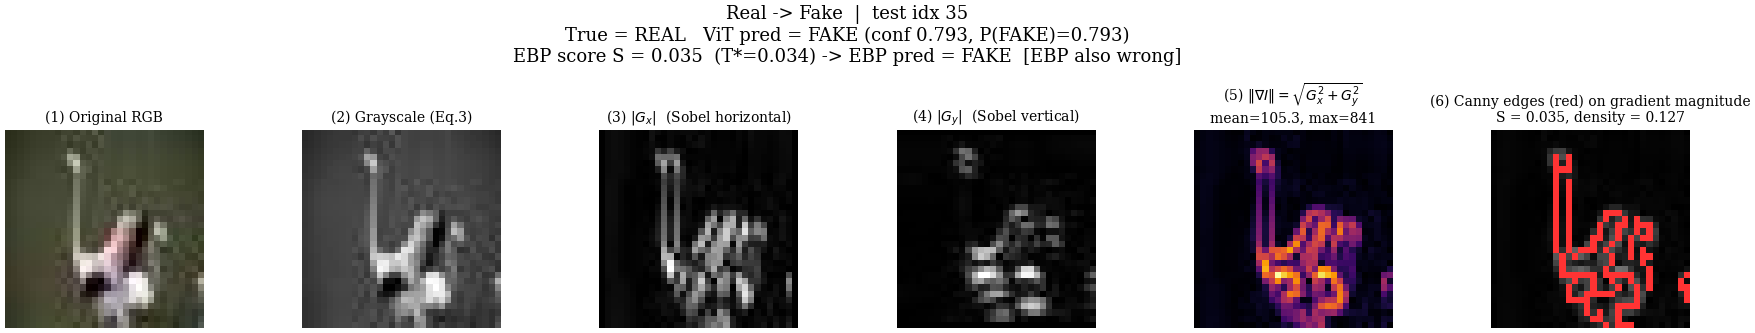

  idx   35: grad_mean=105.3, S=0.035, edge_density=0.127


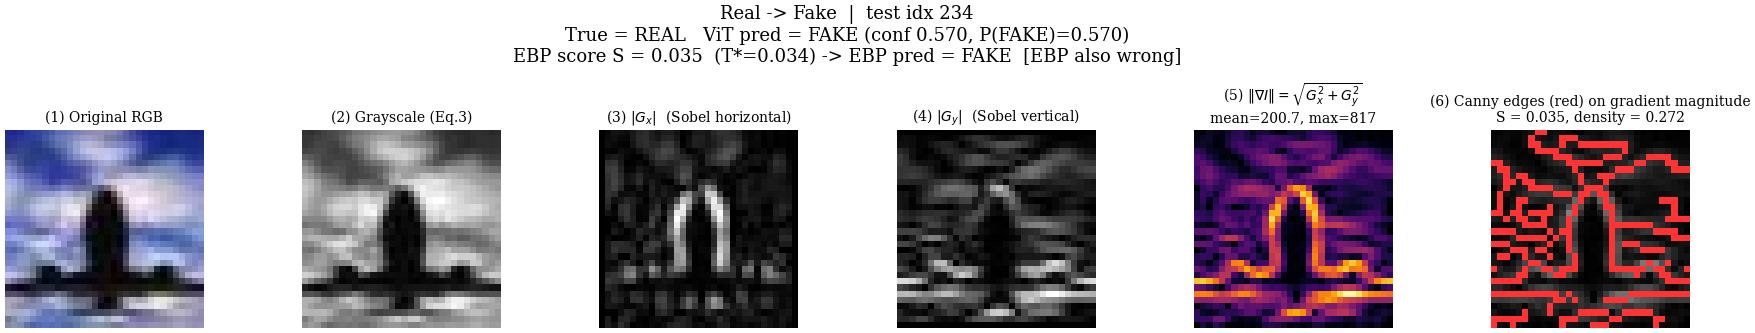

  idx  234: grad_mean=200.7, S=0.035, edge_density=0.272


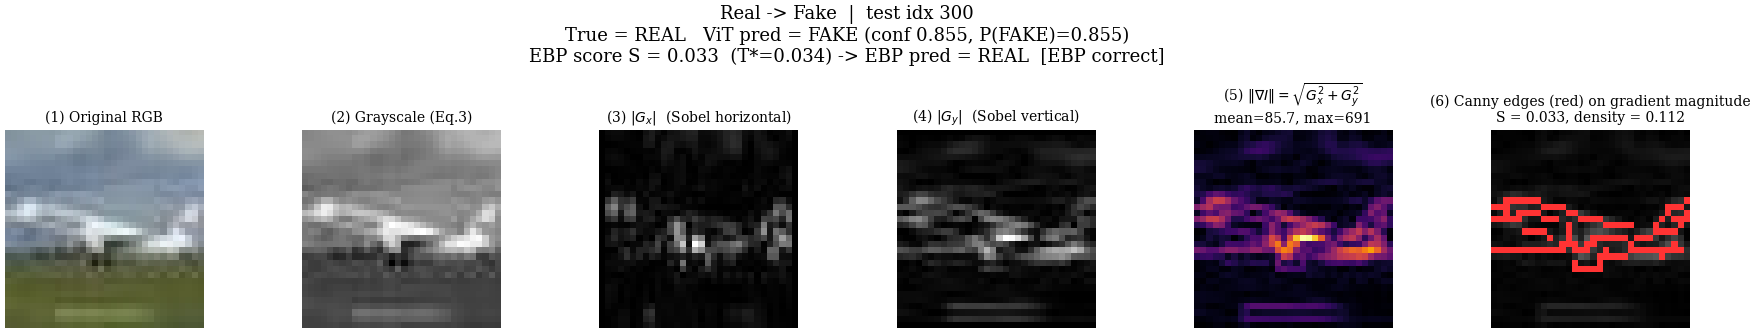

  idx  300: grad_mean=85.7, S=0.033, edge_density=0.112


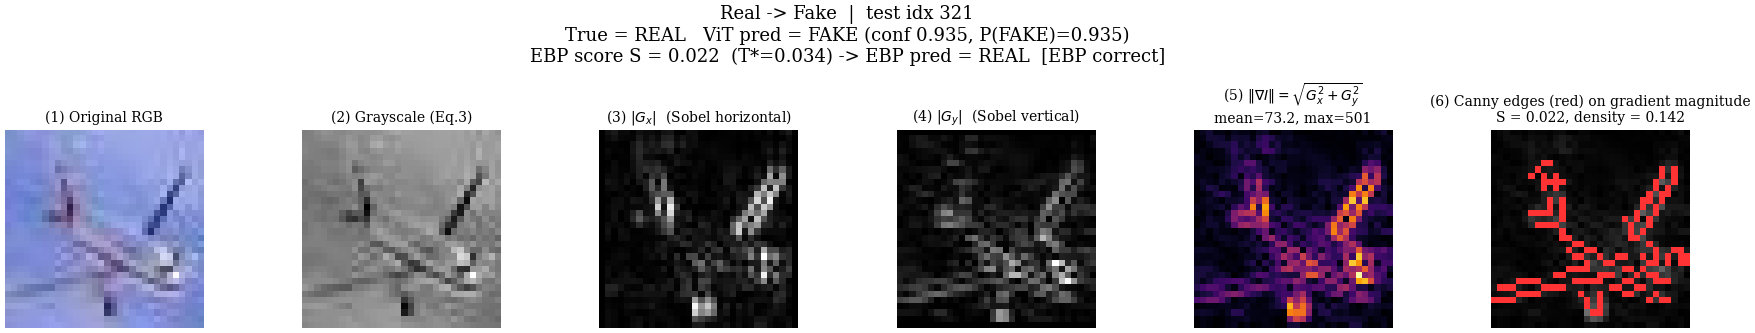

  idx  321: grad_mean=73.2, S=0.022, edge_density=0.142


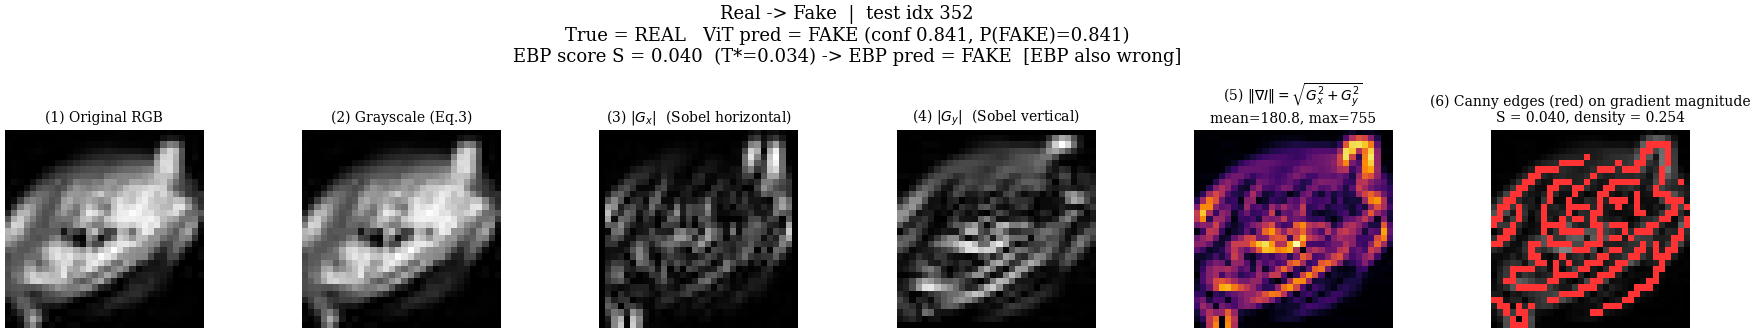

  idx  352: grad_mean=180.8, S=0.040, edge_density=0.254


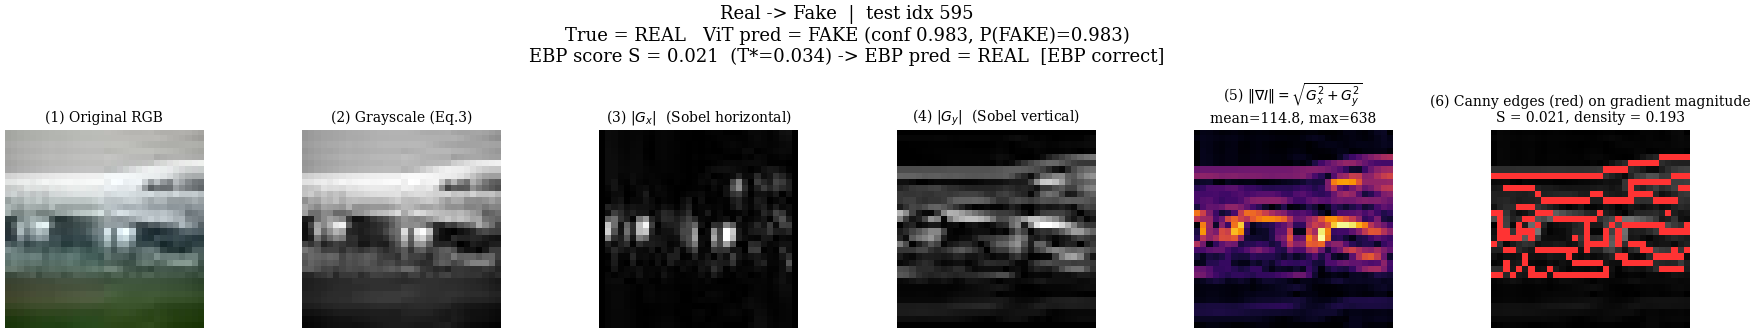

  idx  595: grad_mean=114.8, S=0.021, edge_density=0.193


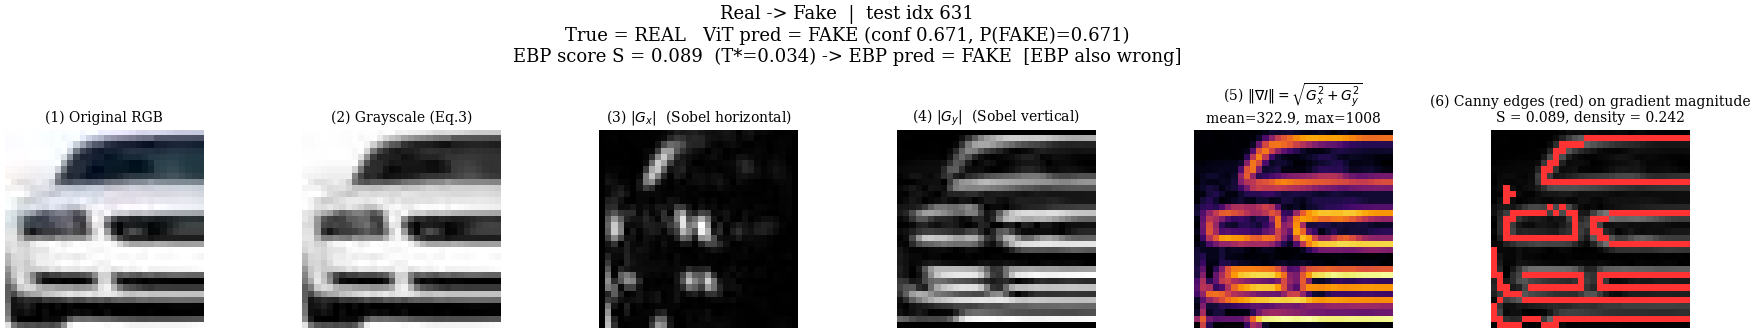

  idx  631: grad_mean=322.9, S=0.089, edge_density=0.242


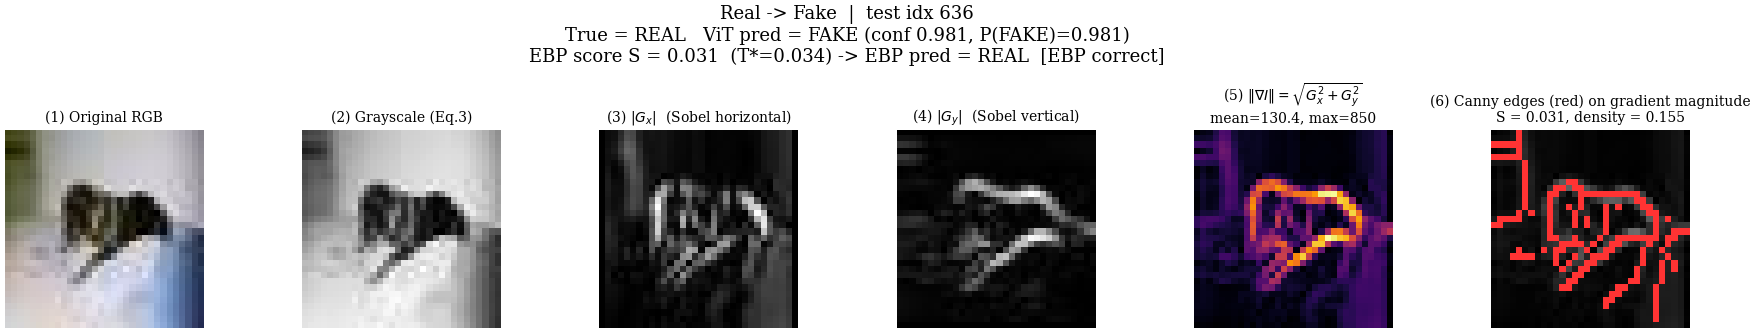

  idx  636: grad_mean=130.4, S=0.031, edge_density=0.155

===== Fake -> Real: showing 8/29 images =====


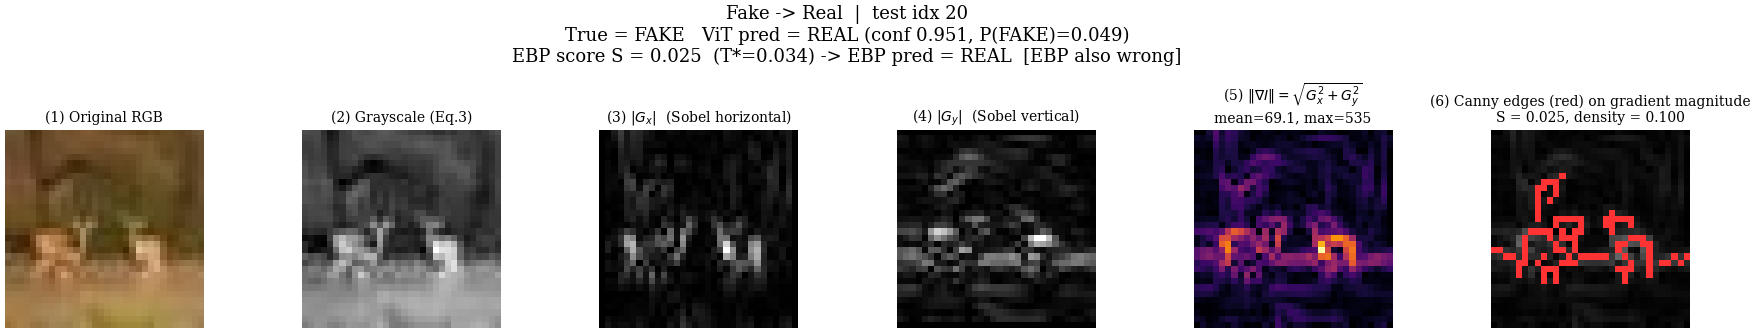

  idx   20: grad_mean=69.1, S=0.025, edge_density=0.100


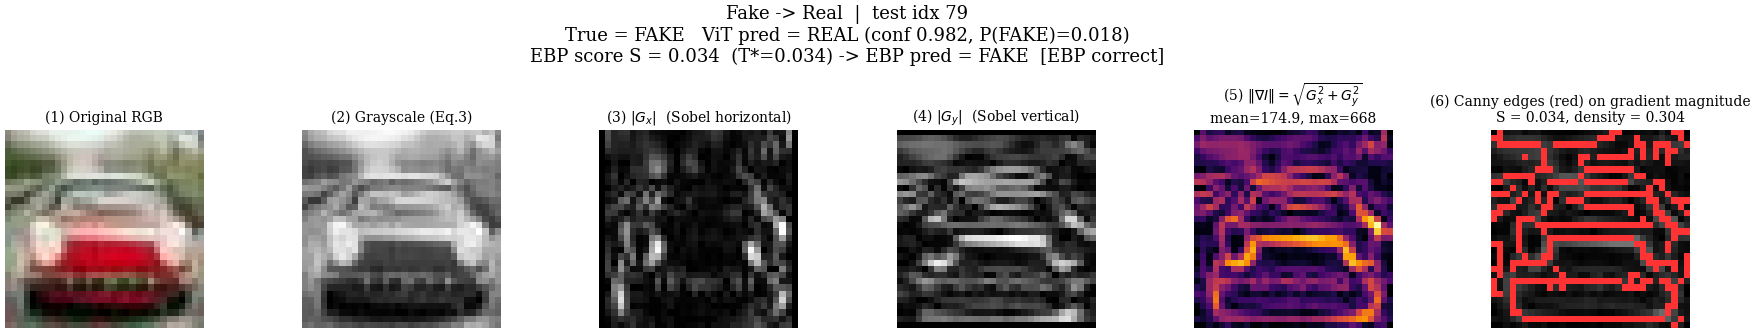

  idx   79: grad_mean=174.9, S=0.034, edge_density=0.304


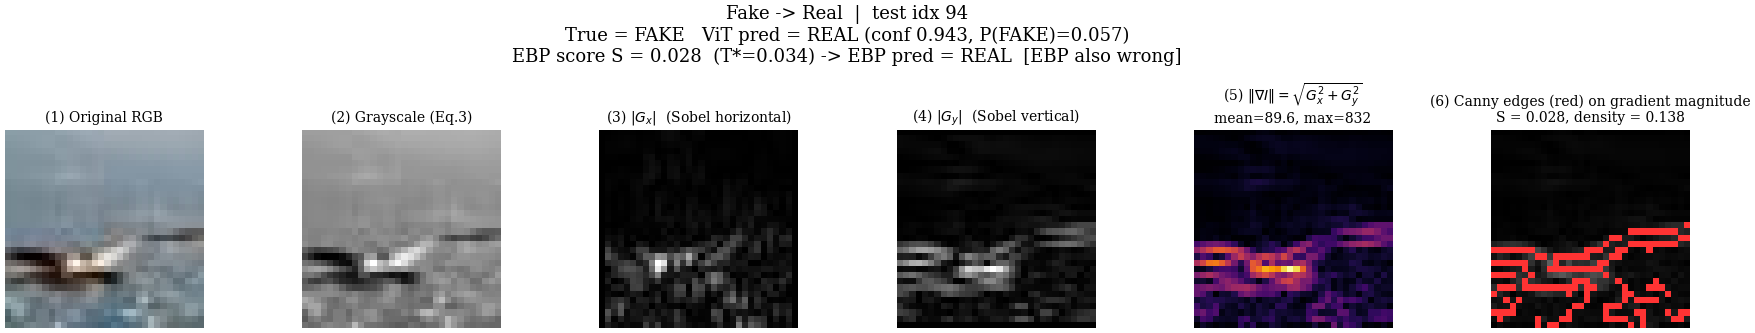

  idx   94: grad_mean=89.6, S=0.028, edge_density=0.138


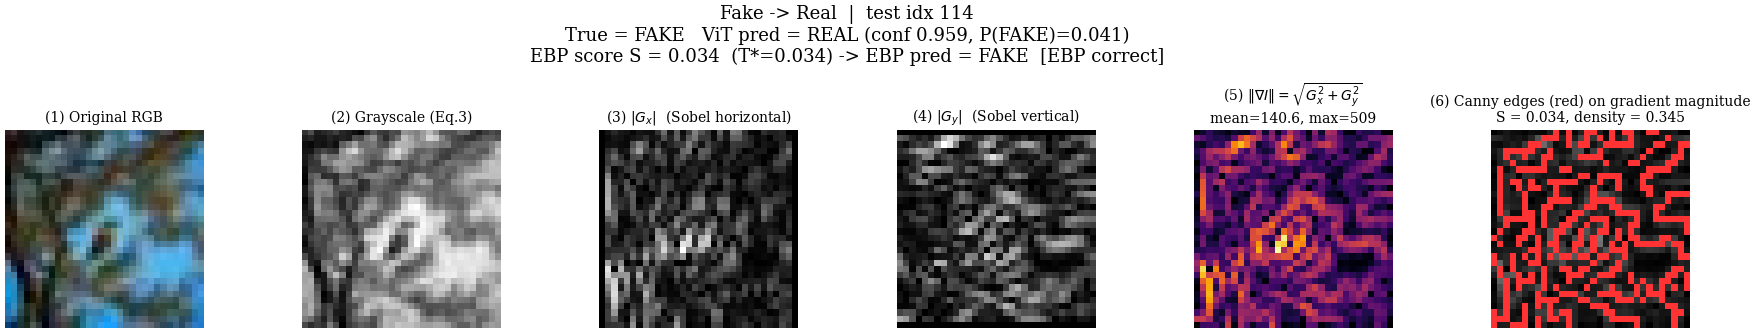

  idx  114: grad_mean=140.6, S=0.034, edge_density=0.345


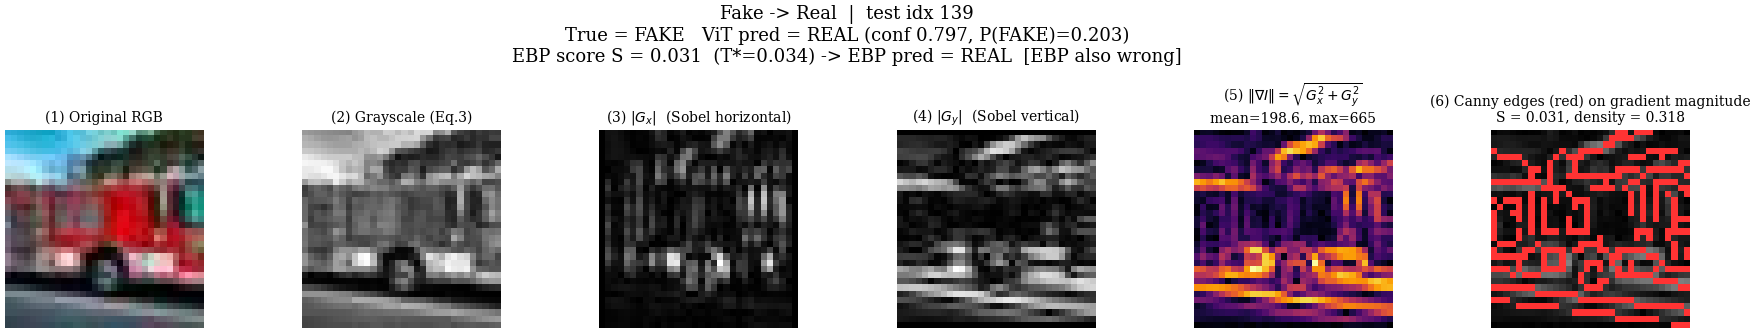

  idx  139: grad_mean=198.6, S=0.031, edge_density=0.318


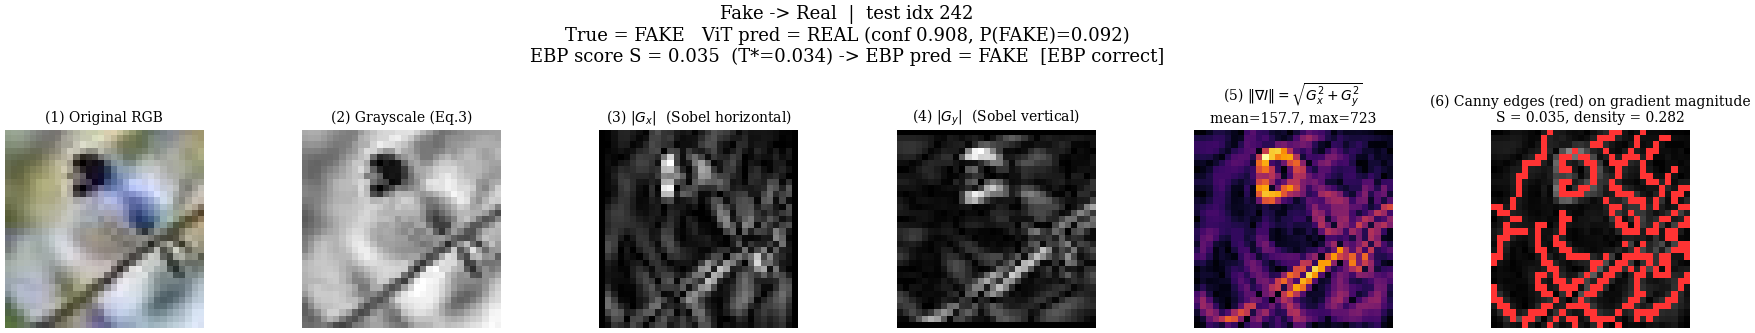

  idx  242: grad_mean=157.7, S=0.035, edge_density=0.282


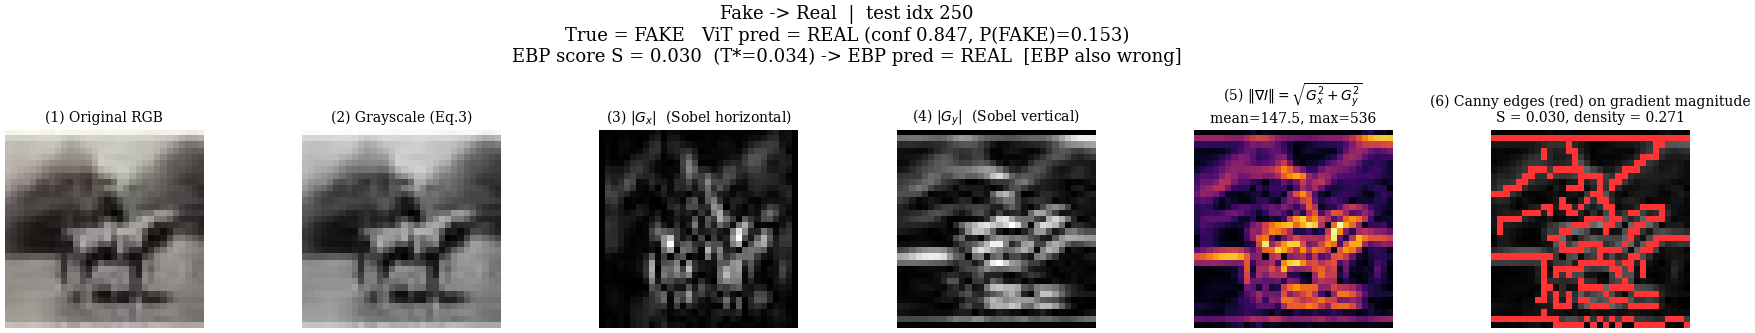

  idx  250: grad_mean=147.5, S=0.030, edge_density=0.271


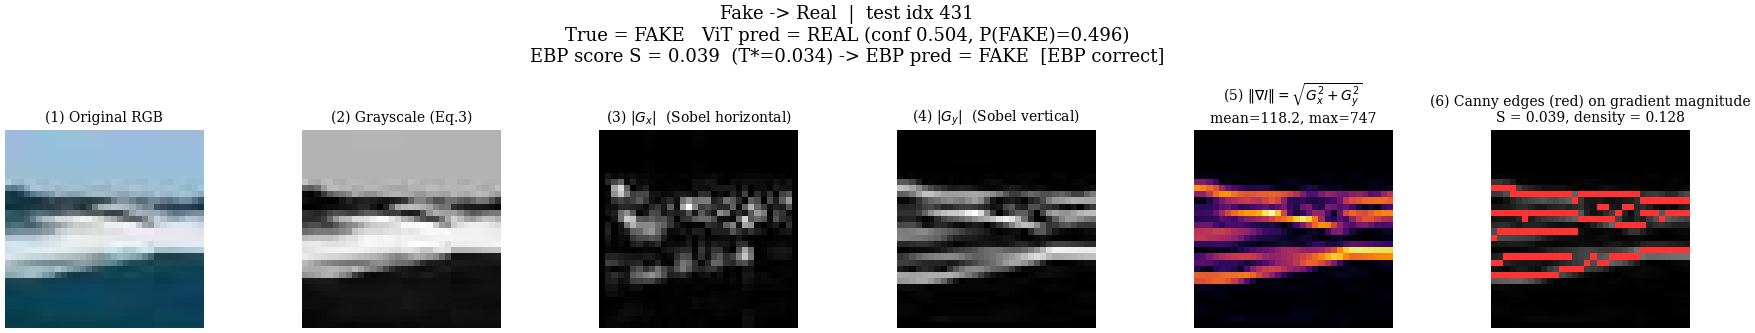

  idx  431: grad_mean=118.2, S=0.039, edge_density=0.128

Saved misclassified gradient figures to: /content/outputs/misclassified_gradients_vit_only


In [13]:
# ============================================================
# CELL 13b: GRADIENT IMAGES FOR MISCLASSIFIED ViT SAMPLES (error analysis)
# ============================================================
# Analyses the ViT-only baseline (Mode 1 / Cell 10) -- the confusion
# matrix [[REAL->REAL, REAL->FAKE], [FAKE->REAL, FAKE->FAKE]].
# Two off-diagonal error groups:
#   - Real -> Fake : gt = REAL but ViT predicts FAKE   (cell [0,1])
#   - Fake -> Real : gt = FAKE but ViT predicts REAL   (cell [1,0])
# Each error image -> 6-panel gradient pipeline (Sobel Gx/Gy, |grad|,
# Canny) for feature-level XAI: shows WHY ViT failed at the edge-feature
# level, and whether the EBP score S would have recovered it.
#
# NO LEAK: gt_test is used ONLY to SELECT which images to inspect
# (post-hoc error analysis), NOT in any prediction logic. vit_pred is
# the original ViT prediction from Cell 10, not overwritten by any mode.

import os
import numpy as np
from thesis_explain import show_gradient_panel   # imported in Cell 2

# --- 13b.1  Error masks from gt_test (Cell 13) and vit_pred (Cell 10) -
gt_test  = np.asarray(gt_test)
vit_pred = np.asarray(vit_pred)

mask_real_as_fake = (gt_test == REAL_ID) & (vit_pred == FAKE_ID)   # Real -> Fake
mask_fake_as_real = (gt_test == FAKE_ID) & (vit_pred == REAL_ID)   # Fake -> Real

idx_real_as_fake = np.where(mask_real_as_fake)[0]
idx_fake_as_real = np.where(mask_fake_as_real)[0]

print(f"Real -> Fake (cell [0,1]) : {len(idx_real_as_fake)} images")
print(f"Fake -> Real (cell [1,0]) : {len(idx_fake_as_real)} images")
print(f"Total errors = {len(idx_real_as_fake) + len(idx_fake_as_real)} / {len(gt_test)}"
      f"  ->  ViT-only acc = {(gt_test == vit_pred).mean()*100:.2f}%")

# --- 13b.2  Output directory -----------------------------------------
err_dir = os.path.join(CONFIG['output_dir'], 'misclassified_gradients_vit_only')
os.makedirs(err_dir, exist_ok=True)

# --- 13b.3  Render gradient panels for one error group ---------------
MAX_SHOW = 8     # [NOT STATED IN PAPER] -- max images per group.
                 # Set to None to render ALL error images in the group.

def show_error_gradients(indices, err_name, file_prefix):
    """Render a 6-panel gradient figure for each misclassified ViT image."""
    if len(indices) == 0:
        print(f"  (no images in group {err_name})")
        return
    shown = indices if MAX_SHOW is None else indices[:MAX_SHOW]
    print(f"\n===== {err_name}: showing {len(shown)}/{len(indices)} images =====")
    for rank, i in enumerate(shown):
        i = int(i)
        ebp_pred = FAKE_ID if test_scores[i] >= T_star else REAL_ID
        ebp_fix  = "EBP correct" if ebp_pred == gt_test[i] else "EBP also wrong"
        title = (
            f"{err_name}  |  test idx {i}\n"
            f"True = {id2label[int(gt_test[i])]}   "
            f"ViT pred = {id2label[int(vit_pred[i])]} "
            f"(conf {vit_conf_test[i]:.3f}, P(FAKE)={vit_pf_test[i]:.3f})\n"
            f"EBP score S = {test_scores[i]:.3f}  (T*={T_star:.3f}) "
            f"-> EBP pred = {id2label[ebp_pred]}  [{ebp_fix}]"
        )
        save_path = os.path.join(err_dir, f"{file_prefix}_{rank:02d}_idx{i}.png")
        fig, stats = show_gradient_panel(
            imgs_test[i],
            blur_ksize=CONFIG['gaussian_ksize'],
            blur_sigma=CONFIG['gaussian_sigma'],
            title=title,
            save_path=save_path,
            show=True,
        )
        print(f"  idx {i:4d}: grad_mean={stats['grad_mean']:.1f}, "
              f"S={stats['ebp_score']:.3f}, edge_density={stats['edge_density']:.3f}")

# --- 13b.4  Run for both ViT-only error groups -----------------------
show_error_gradients(idx_real_as_fake, "Real -> Fake", "real_as_fake")
show_error_gradients(idx_fake_as_real, "Fake -> Real", "fake_as_real")

print(f"\nSaved misclassified gradient figures to: {err_dir}")


In [14]:
# ============================================================
# CELL 12b: MODE 0 -- DIAGNOSTIC (REPRODUCE OLD LEAKED RESULT)
# ============================================================
# WHY KEEP THIS CELL: the thesis needs to show, side by side, the old
# (invalid) and new (valid) numbers, so the advisor's review trail is
# documented. We compute the OLD leaked accuracy here -- LABELED AS
# INVALID -- and report it only as a diagnostic, never as a main result.

ebp_pred_test = np.where(test_scores >= T_star, FAKE_ID, REAL_ID)

# Reproduce the old leak: replace ONLY images ViT got wrong, using
# ground truth to identify them. This is the bug we are fixing.
leaked_pred = vit_pred.copy()
misclassified_mask = (leaked_pred != gt_test)         # <-- uses gt (LEAK)
leaked_pred[misclassified_mask] = ebp_pred_test[misclassified_mask]

n_mis  = int(misclassified_mask.sum())
n_flip = int(((leaked_pred == gt_test) & misclassified_mask).sum())
print('=' * 60)
print(' MODE 0  --  OLD LEAKED LOGIC (kept only as diagnostic)')
print('=' * 60)
print(f'  ViT errors on test            : {n_mis}/{len(gt_test)} '
      f'({n_mis/len(gt_test)*100:.2f}%)')
print(f'  EBP fixes among those errors  : {n_flip}/{n_mis} '
      f'({n_flip/max(n_mis,1)*100:.1f}%  -- random would be ~50%)')
print('  WARNING: this number IS NOT a valid inference accuracy.')
print('  It uses test ground truth to decide which images to correct.')
print('  Reported below ONLY to document the bug fix in the thesis.')
print('=' * 60)

m_leak = format_metrics_dict(
    y_true=gt_test, y_pred=leaked_pred,
    y_score=None, pos_label=FAKE_ID,
)
pretty_print_metrics('Mode 0: Oracle-leaked ViT+EBP (INVALID)', m_leak)

 MODE 0  --  OLD LEAKED LOGIC (kept only as diagnostic)
  ViT errors on test            : 50/1200 (4.17%)
  EBP fixes among those errors  : 19/50 (38.0%  -- random would be ~50%)
  It uses test ground truth to decide which images to correct.
  Reported below ONLY to document the bug fix in the thesis.
------------------------------------------------------------
 Mode 0: Oracle-leaked ViT+EBP (INVALID)
------------------------------------------------------------
   Accuracy (%)  :  97.417
   F1-Score (%)  :  97.397
   Precision (%) :  98.139
   Recall (%)    :  96.667
   Mean IoU (%)  :  94.963
------------------------------------------------------------


In [15]:
# ============================================================
# CELL 12c: MODE 1 -- ViT ONLY (BASELINE, no EBP)
# ============================================================
# Same predictions as Cell 10 but now reported with the full metric
# bundle (including AUC-ROC and PR-AUC) and FAKE as positive class,
# per the advisor's recommendation.

m_vit = format_metrics_dict(
    y_true=gt_test, y_pred=vit_pred,
    y_score=vit_pf_test,                  # P(FAKE) as score for FAKE-positive
    pos_label=FAKE_ID,
)
pretty_print_metrics('Mode 1: Fine-tuned ViT only', m_vit)

------------------------------------------------------------
 Mode 1: Fine-tuned ViT only
------------------------------------------------------------
   Accuracy (%)  :  95.833
   F1-Score (%)  :  95.805
   Precision (%) :  96.453
   Recall (%)    :  95.167
   Mean IoU (%)  :  92.000
   AUC-ROC (%)   :  99.302
   PR-AUC (%)    :  99.245
------------------------------------------------------------


In [16]:
# ============================================================
# CELL 12d: MODE 2 -- EBP ONLY  (advisor option A)
# ============================================================
# Apply EBP threshold T* (calibrated on VAL in Cell 11) to ALL test
# images and use the result as the final prediction. This measures
# whether EBP, on its own, can discriminate REAL from FAKE.
#
# Per advisor: medians of REAL and FAKE EBP scores are nearly identical
# (delta ~ 0.0007 in the current run). We expect EBP-only accuracy to
# be barely above chance. Reporting this honestly is itself a
# scientific finding for the thesis.

# `ebp_pred_test` already built in Cell 12b
m_ebp = format_metrics_dict(
    y_true=gt_test, y_pred=ebp_pred_test,
    y_score=test_scores,                  # higher score == more FAKE-like
    pos_label=FAKE_ID,
)
pretty_print_metrics('Mode 2: EBP only', m_ebp)

------------------------------------------------------------
 Mode 2: EBP only
------------------------------------------------------------
   Accuracy (%)  :  52.000
   F1-Score (%)  :  49.474
   Precision (%) :  52.222
   Recall (%)    :  47.000
   Mean IoU (%)  :  35.061
   AUC-ROC (%)   :  51.709
   PR-AUC (%)    :  52.181
------------------------------------------------------------


In [17]:
# ============================================================
# CELL 12e: MODE 3 -- CONFIDENCE-GATED ViT + EBP  (advisor option C)
# ============================================================
# Logic: if ViT is confident, trust ViT. If ViT is uncertain
# (max softmax < tau), defer to EBP. The threshold tau is selected
# on the VALIDATION set to maximize F1 (FAKE = positive). Test data
# never enters the calibration loop.
#
# Why this is leak-free:
#   - tau is chosen using val labels only.
#   - The gating decision per test image uses only:
#       * ViT softmax (no labels)
#       * EBP score   (no labels)
#       * tau         (val-calibrated constant)
#   - No test ground truth is ever consulted.

from sklearn.metrics import f1_score

def gated_predict(vit_pr, vit_cf, ebp_pr, tau):
    """Return ViT prediction unless ViT confidence < tau, then EBP."""
    out = vit_pr.copy()
    low_conf = vit_cf < tau
    out[low_conf] = ebp_pr[low_conf]
    return out

# Precompute EBP predictions on val (same threshold T*)
ebp_pred_val = np.where(val_scores >= T_star, FAKE_ID, REAL_ID)

# Grid search tau on VALIDATION. [NOT STATED IN PAPER] -- grid + objective
# are our design choices; we use FAKE-positive F1 per advisor's note.
tau_grid = np.linspace(0.50, 1.00, 51)
val_f1s  = []
for tau in tau_grid:
    val_gated = gated_predict(vit_pred_val, vit_conf_val, ebp_pred_val, tau)
    val_f1s.append(f1_score(gt_val, val_gated, pos_label=FAKE_ID,
                            zero_division=0))
val_f1s   = np.asarray(val_f1s)
best_idx  = int(np.argmax(val_f1s))
tau_star  = float(tau_grid[best_idx])
print(f'Selected tau* = {tau_star:.3f}  '
      f'(val F1 at tau* = {val_f1s[best_idx]*100:.2f}%, '
      f'val F1 at tau=1.0 [always EBP] = {val_f1s[-1]*100:.2f}%, '
      f'val F1 at tau=0.5 [almost always ViT] = {val_f1s[0]*100:.2f}%)')

# Apply on TEST
gated_pred_test = gated_predict(vit_pred, vit_conf_test, ebp_pred_test, tau_star)

# For AUC, build a "gated score": use ViT P(FAKE) for confident samples,
# normalized EBP score for low-confidence samples. [NOT STATED IN PAPER]
# This is a heuristic so we can also report AUC for this mode; the
# final prediction itself does not depend on the score.
ebp_score_norm = (test_scores - np.min(test_scores)) / \
                 (np.max(test_scores) - np.min(test_scores) + 1e-9)
gated_score = np.where(vit_conf_test < tau_star, ebp_score_norm, vit_pf_test)

m_gated = format_metrics_dict(
    y_true=gt_test, y_pred=gated_pred_test,
    y_score=gated_score, pos_label=FAKE_ID,
)
m_gated['_tau_star'] = tau_star
pretty_print_metrics(f'Mode 3: Confidence-gated ViT+EBP (tau*={tau_star:.3f})',
                     m_gated)

Selected tau* = 0.740  (val F1 at tau* = 96.76%, val F1 at tau=1.0 [always EBP] = 51.57%, val F1 at tau=0.5 [almost always ViT] = 96.59%)
------------------------------------------------------------
 Mode 3: Confidence-gated ViT+EBP (tau*=0.740)
------------------------------------------------------------
   Accuracy (%)  :  95.417
   F1-Score (%)  :  95.397
   Precision (%) :  95.798
   Recall (%)    :  95.000
   Mean IoU (%)  :  91.235
   AUC-ROC (%)   :  99.109
   PR-AUC (%)    :  98.242
------------------------------------------------------------


In [18]:
# ============================================================
# CELL 12f: MODE 4 -- LOGISTIC REGRESSION FUSION  (advisor option B)
# ============================================================
# Train a small fusion classifier on validation set features, then
# predict on the test set. Features per image:
#   x1 = P(FAKE) from ViT softmax        -- ViT global signal
#   x2 = log1p(EBP score)                 -- edge signal, log-compressed
#   x3 = ViT confidence (max softmax)     -- redundancy / interaction
#
# Why this is leak-free:
#   - LogReg is fit ONLY on validation set features and labels.
#   - Predictions on test use the frozen scaler + classifier.
#   - No test labels are touched in fitting.
#
# We use class_weight='balanced' as the validation set may not be
# perfectly balanced after split.  [NOT STATED IN PAPER]

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

def build_fusion_features(pf, ebp, conf):
    """Stack three features into an (N, 3) matrix."""
    return np.column_stack([pf, np.log1p(ebp), conf])

X_val  = build_fusion_features(vit_pf_val,  val_scores,  vit_conf_val)
X_test = build_fusion_features(vit_pf_test, test_scores, vit_conf_test)

# Fit scaler + LogReg on validation only
scaler = StandardScaler().fit(X_val)
X_val_s  = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

# y = 1 means FAKE (per advisor: FAKE is positive class)
y_val_bin = (gt_val == FAKE_ID).astype(int)

clf = LogisticRegression(
    class_weight='balanced',
    max_iter=500,
    random_state=CONFIG.get('seed', 42),
    solver='lbfgs',
)
clf.fit(X_val_s, y_val_bin)

# Report learned coefficients -- useful for the thesis to explain how
# the model combines ViT and EBP signals.
coef = clf.coef_[0]
print(f'LogReg coefficients  (scaled features):')
print(f'   w_ViT_P(FAKE)     = {coef[0]:+.3f}')
print(f'   w_log1p(EBP)      = {coef[1]:+.3f}')
print(f'   w_ViT_confidence  = {coef[2]:+.3f}')
print(f'   intercept         = {clf.intercept_[0]:+.3f}')

# Predict on TEST
fusion_pf_test  = clf.predict_proba(X_test_s)[:, 1]    # P(FAKE)
fusion_pred     = np.where(fusion_pf_test >= 0.5, FAKE_ID, REAL_ID)

m_fusion = format_metrics_dict(
    y_true=gt_test, y_pred=fusion_pred,
    y_score=fusion_pf_test, pos_label=FAKE_ID,
)
pretty_print_metrics('Mode 4: LogReg fusion (val-trained)', m_fusion)

LogReg coefficients  (scaled features):
   w_ViT_P(FAKE)     = +3.597
   w_log1p(EBP)      = -0.007
   w_ViT_confidence  = -0.037
   intercept         = -0.005
------------------------------------------------------------
 Mode 4: LogReg fusion (val-trained)
------------------------------------------------------------
   Accuracy (%)  :  95.833
   F1-Score (%)  :  95.812
   Precision (%) :  96.296
   Recall (%)    :  95.333
   Mean IoU (%)  :  92.000
   AUC-ROC (%)   :  99.261
   PR-AUC (%)    :  99.103
------------------------------------------------------------



 RESULTS TABLE  (positive class = FAKE)
                        Mode       Kind  Accuracy (%)  F1 (%)  Precision (%)  Recall (%)  mIoU (%)  AUC-ROC (%)  PR-AUC (%)
Mode 0: Old leaked (INVALID) diagnostic         97.42   97.40          98.14       96.67     94.96          NaN         NaN
            Mode 1: ViT only   baseline         95.83   95.81          96.45       95.17     92.00        99.30       99.24
            Mode 2: EBP only    no-leak         52.00   49.47          52.22       47.00     35.06        51.71       52.18
    Mode 3: Confidence-gated    no-leak         95.42   95.40          95.80       95.00     91.23        99.11       98.24
       Mode 4: LogReg fusion    no-leak         95.83   95.81          96.30       95.33     92.00        99.26       99.10
[OK] Saved /content/outputs/table_inference_modes.csv and /content/outputs/table_inference_modes.md


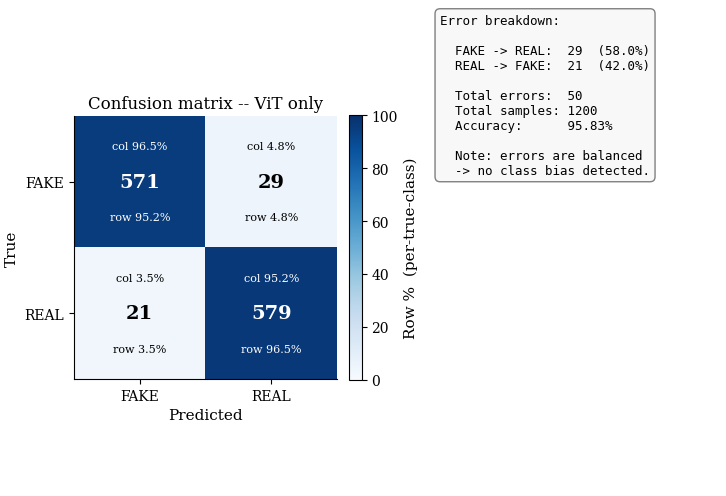

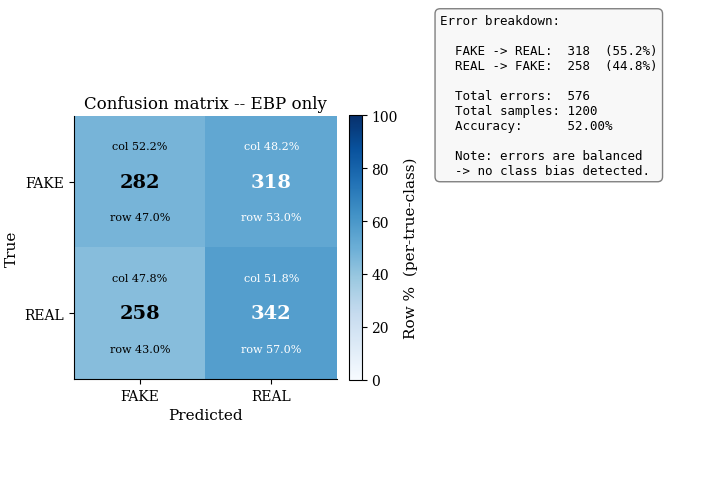

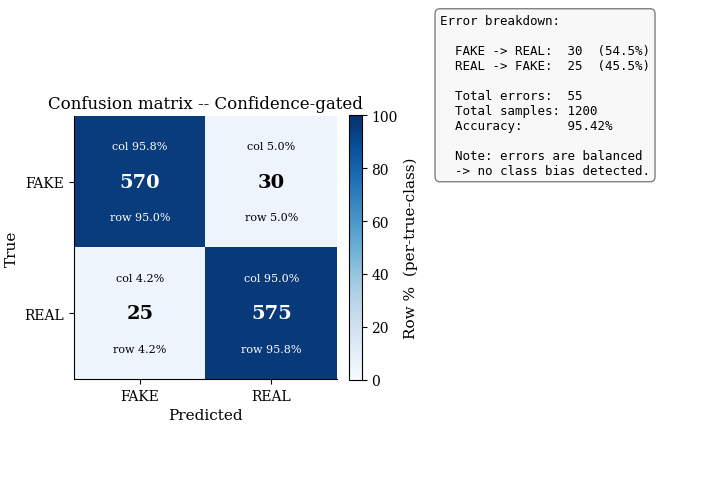

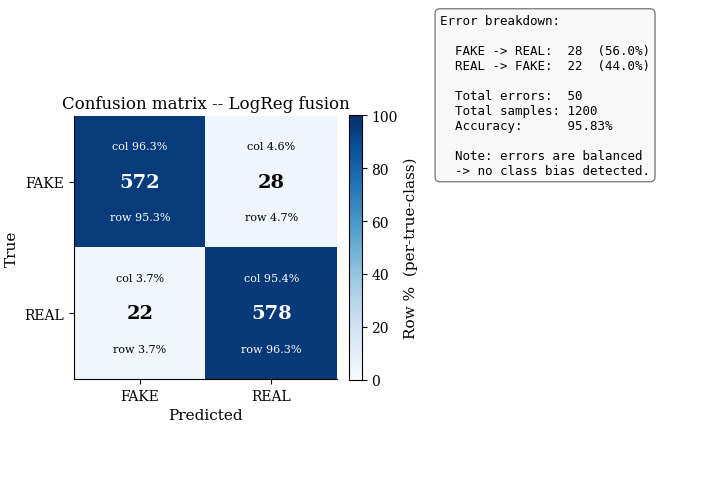

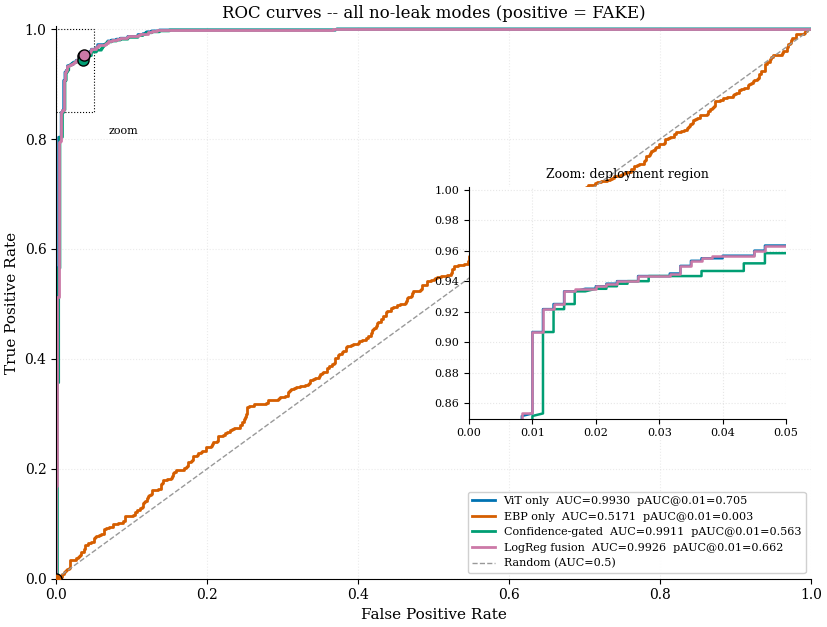


ROC table (partial AUCs):
            mode     AUC  pAUC@0.01  pAUC@0.05  pAUC@0.10  op_FPR  op_TPR
        ViT only  0.9930     0.7049     0.8962     0.9369  0.0350  0.9517
        EBP only  0.5171     0.0025     0.0342     0.0648  0.0000  0.0000
Confidence-gated  0.9911     0.5628     0.8621     0.9184  0.0350  0.9433
   LogReg fusion  0.9926     0.6622     0.8877     0.9327  0.0367  0.9533


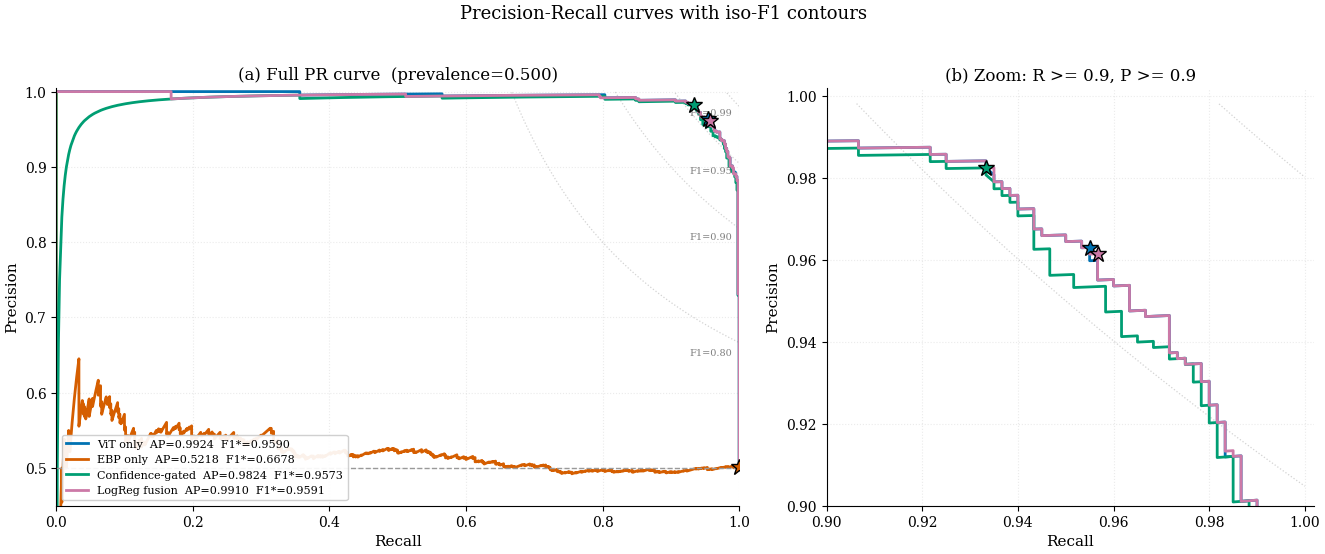


PR table (best F1 per mode):
            mode      AP  best_F1  best_F1_precision  best_F1_recall
        ViT only  0.9924   0.9590             0.9630          0.9550
        EBP only  0.5218   0.6678             0.5013          1.0000
Confidence-gated  0.9824   0.9573             0.9825          0.9333
   LogReg fusion  0.9910   0.9591             0.9615          0.9567


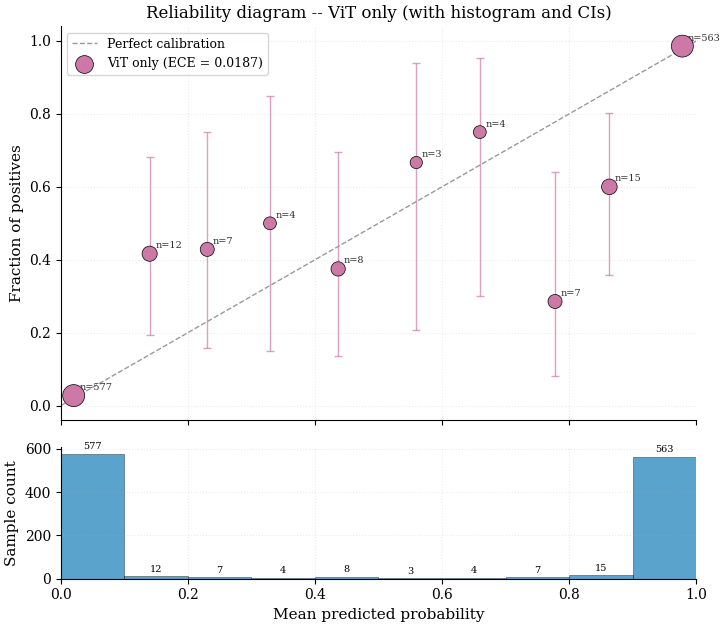


ViT only ECE = 0.0187


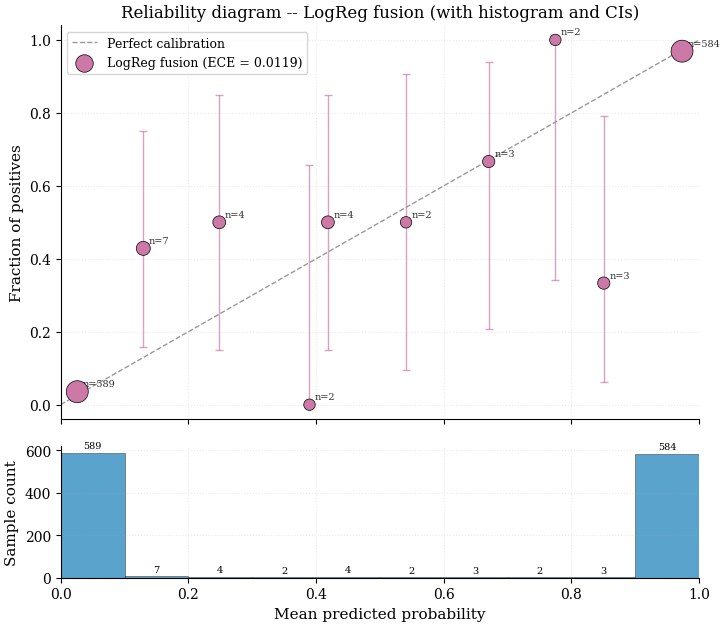

LogReg fusion ECE = 0.0119


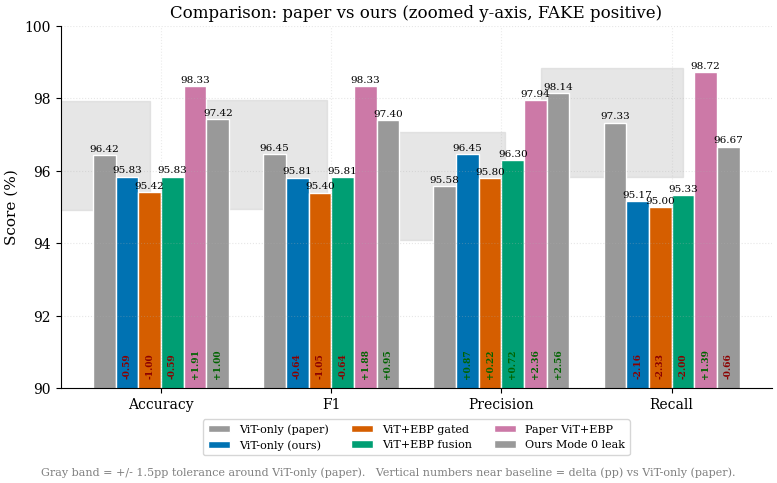


Tolerance check  (Mode 1 ViT-only  vs  paper Table 6 ViT-only)
       Metric  Paper (%)  Ours (%)  Delta (pp)       Status
 Accuracy (%)      96.42 95.833333   -0.586667         PASS
 F1-Score (%)      96.45 95.805369   -0.644631         PASS
Precision (%)      95.58 96.452703    0.872703         PASS
   Recall (%)      97.33 95.166667   -2.163333 NEEDS REVIEW
 Mean IoU (%)      93.08 91.999672   -1.080328         PASS


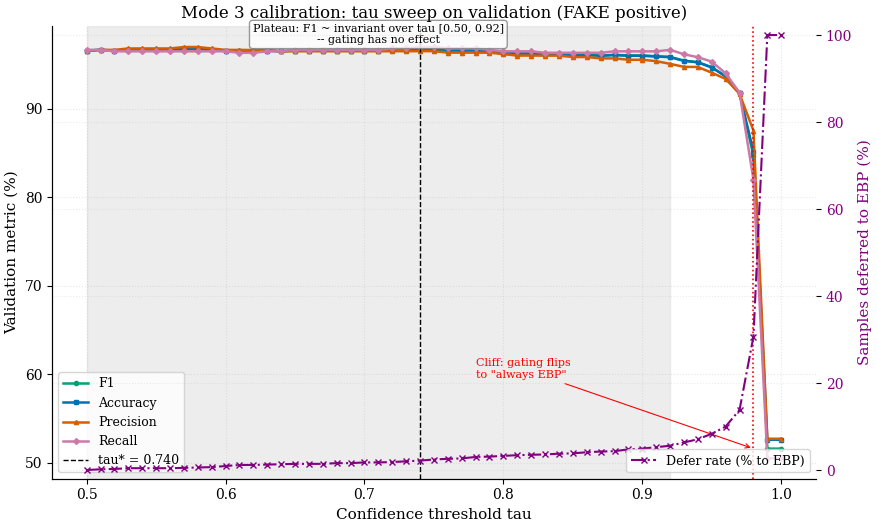

(<Figure size 900x550 with 2 Axes>,
      tau        F1  Accuracy  Precision    Recall  defer_rate
 0   0.50  0.965862  0.965833   0.965058  0.966667    0.000000
 1   0.51  0.966667  0.966667   0.966667  0.966667    0.001667
 2   0.52  0.965805  0.965833   0.966611  0.965000    0.002500
 3   0.53  0.966611  0.966667   0.968227  0.965000    0.004167
 4   0.54  0.966611  0.966667   0.968227  0.965000    0.004167
 5   0.55  0.966611  0.966667   0.968227  0.965000    0.004167
 6   0.56  0.966611  0.966667   0.968227  0.965000    0.004167
 7   0.57  0.967419  0.967500   0.969849  0.965000    0.005000
 8   0.58  0.967419  0.967500   0.969849  0.965000    0.005833
 9   0.59  0.966611  0.966667   0.968227  0.965000    0.006667
 10  0.60  0.965805  0.965833   0.966611  0.965000    0.009167
 11  0.61  0.964942  0.965000   0.966555  0.963333    0.011667
 12  0.62  0.964942  0.965000   0.966555  0.963333    0.011667
 13  0.63  0.965805  0.965833   0.966611  0.965000    0.012500
 14  0.64  0.965000

In [19]:
# ============================================================
# CELL 13: COMPARISON TABLE + VISUALIZATIONS
# ============================================================
# Builds the final metric table and the canonical figures for the
# thesis Chapter 4 (Experiments) and Chapter 5 (Discussion).
# Every figure is saved as PNG + PDF (via thesis_utils.save_figure).

import pandas as pd
import os
import matplotlib.pyplot as plt

# Re-import from thesis_utils to override the local `plot_confusion_matrix`
# that Cell 10 defined (which lacks save_path/show parameters).
# Cell 10's local def shadows the imported one until we re-import here.
from thesis_utils import (
    plot_confusion_matrix, plot_calibration, plot_comparison_bar,
    save_figure, save_results_csv, tolerance_check_table,
    FIGSIZE, PALETTE,
)

OUT = CONFIG.get('output_dir', '/content/outputs')
os.makedirs(OUT, exist_ok=True)

# ---- 13.1  Result table ----
def _pack(name, m, mode_kind):
    row = {
        'Mode'        : name,
        'Kind'        : mode_kind,
        'Accuracy (%)': m['Accuracy (%)'],
        'F1 (%)'      : m['F1-Score (%)'],
        'Precision (%)': m['Precision (%)'],
        'Recall (%)'  : m['Recall (%)'],
        'mIoU (%)'    : m['Mean IoU (%)'],
        'AUC-ROC (%)' : m.get('AUC-ROC (%)', np.nan),
        'PR-AUC (%)'  : m.get('PR-AUC (%)',  np.nan),
    }
    return row

result_df = pd.DataFrame([
    _pack('Mode 0: Old leaked (INVALID)', m_leak,   'diagnostic'),
    _pack('Mode 1: ViT only',             m_vit,    'baseline'),
    _pack('Mode 2: EBP only',             m_ebp,    'no-leak'),
    _pack('Mode 3: Confidence-gated',     m_gated,  'no-leak'),
    _pack('Mode 4: LogReg fusion',        m_fusion, 'no-leak'),
])
print('\n' + '=' * 80)
print(' RESULTS TABLE  (positive class = FAKE)')
print('=' * 80)
print(result_df.to_string(index=False, float_format=lambda x: f'{x:7.2f}'))

save_results_csv(result_df,
                 os.path.join(OUT, 'table_inference_modes.csv'))

# ---- 13.2  Confusion matrices for each no-leak mode ----
from sklearn.metrics import confusion_matrix
from sklearn.metrics import confusion_matrix

for name, pred in [
    ('ViT only',         vit_pred),
    ('EBP only',         ebp_pred_test),
    ('Confidence-gated', gated_pred_test),
    ('LogReg fusion',    fusion_pred),
]:
    cm = confusion_matrix(gt_test, pred)
    safe = name.lower().replace(' ', '_').replace('+', '')
    # Detailed CM: shows count + row% + col% + error breakdown sidebar
    plot_confusion_matrix_detailed(
        cm, CONFIG['class_names'],
        title=f'Confusion matrix -- {name}',
        save_path=os.path.join(OUT, f'fig_cm_{safe}.png'),
    )

# ---- 13.3  ROC + PR + Calibration for the two scoring modes ----
# Mode 1 (ViT) and Mode 4 (LogReg fusion) both expose well-defined
# probabilities; Mode 2's score is the raw EBP S which is also valid.
# Mode 3's gated score is a heuristic, plot it but flag in caption.
scoring_modes = [
    ('ViT only',         vit_pf_test,    PALETTE['real']),
    ('EBP only',         test_scores,    PALETTE['fake']),
    ('Confidence-gated', gated_score,    PALETTE['highlight']),
    ('LogReg fusion',    fusion_pf_test, PALETTE['accent']),
]

# Combined ROC
fig_roc, df_roc = plot_roc_detailed(
    gt_test, scoring_modes, pos_label=FAKE_ID,
    operating_threshold=0.5,
    zoom_fpr_max=0.05, zoom_tpr_min=0.85,
    partial_auc_fprs=(0.01, 0.05, 0.10),
    title='ROC curves -- all no-leak modes (positive = FAKE)',
    save_path=os.path.join(OUT, 'fig_roc_all_modes.png'),
)
print('\nROC table (partial AUCs):')
print(df_roc.to_string(index=False, float_format=lambda x: f'{x:7.4f}'
                       if isinstance(x, float) else str(x)))

# Combined PR
fig_pr, df_pr = plot_pr_detailed(
    gt_test, scoring_modes, pos_label=FAKE_ID,
    iso_f1_levels=(0.80, 0.90, 0.95, 0.99),
    zoom_recall_min=0.90, zoom_precision_min=0.90,
    title='Precision-Recall curves with iso-F1 contours',
    save_path=os.path.join(OUT, 'fig_pr_all_modes.png'),
)
print('\nPR table (best F1 per mode):')
print(df_pr.to_string(index=False, float_format=lambda x: f'{x:7.4f}'
                      if isinstance(x, float) else str(x)))

# ViT only calibration
fig_cal_vit, df_cal_vit, ece_vit = plot_calibration_detailed(
    gt_test, vit_pf_test, pos_label=FAKE_ID,
    label='ViT only',
    title='Reliability diagram -- ViT only (with histogram and CIs)',
    save_path=os.path.join(OUT, 'fig_calibration_vit.png'),
)
print(f'\nViT only ECE = {ece_vit:.4f}')

# LogReg fusion calibration
fig_cal_fus, df_cal_fus, ece_fus = plot_calibration_detailed(
    gt_test, fusion_pf_test, pos_label=FAKE_ID,
    label='LogReg fusion',
    title='Reliability diagram -- LogReg fusion (with histogram and CIs)',
    save_path=os.path.join(OUT, 'fig_calibration_fusion.png'),
)
print(f'LogReg fusion ECE = {ece_fus:.4f}')

# ---- 13.4  Comparison bar (paper vs ours, no-leak modes) ----
bar_df = pd.DataFrame([
    {'Model': 'ViT-only (paper)',  'Accuracy': 96.42, 'F1': 96.45,
     'Precision': 95.58, 'Recall': 97.33},
    {'Model': 'ViT-only (ours)',   'Accuracy': m_vit['Accuracy (%)'],
     'F1': m_vit['F1-Score (%)'],
     'Precision': m_vit['Precision (%)'], 'Recall': m_vit['Recall (%)']},
    {'Model': 'ViT+EBP gated',     'Accuracy': m_gated['Accuracy (%)'],
     'F1': m_gated['F1-Score (%)'],
     'Precision': m_gated['Precision (%)'],
     'Recall': m_gated['Recall (%)']},
    {'Model': 'ViT+EBP fusion',    'Accuracy': m_fusion['Accuracy (%)'],
     'F1': m_fusion['F1-Score (%)'],
     'Precision': m_fusion['Precision (%)'],
     'Recall': m_fusion['Recall (%)']},
    # New: include paper's ViT+EBP (Table 6) and our Mode 0 leak result
    # side by side -- this is the strongest visual evidence that the
    # paper likely contains the same Algorithm 3 leak.
    {'Model': 'Paper ViT+EBP',     'Accuracy': 98.33, 'F1': 98.33,
     'Precision': 97.94, 'Recall': 98.72},
    {'Model': 'Ours Mode 0 leak',  'Accuracy': m_leak['Accuracy (%)'],
     'F1': m_leak['F1-Score (%)'],
     'Precision': m_leak['Precision (%)'],
     'Recall': m_leak['Recall (%)']},
])

plot_comparison_bar_detailed(
    bar_df,
    metric_cols=['Accuracy', 'F1', 'Precision', 'Recall'],
    reference_row_label='ViT-only (paper)',
    tolerance_pp=1.5,
    title='Comparison: paper vs ours (zoomed y-axis, FAKE positive)',
    save_path=os.path.join(OUT, 'fig_comparison_paper_vs_ours.png'),
)

# ---- 13.5  Tolerance check vs paper (ViT-only is the relevant row) ----
print('\nTolerance check  (Mode 1 ViT-only  vs  paper Table 6 ViT-only)')
paper_vit = {'Accuracy (%)': 96.42, 'F1-Score (%)': 96.45,
             'Precision (%)': 95.58, 'Recall (%)': 97.33,
             'Mean IoU (%)': 93.08}
tol_df = tolerance_check_table(
    ours={k: m_vit[k] for k in paper_vit},
    paper=paper_vit, tol=1.5,
)
print(tol_df.to_string(index=False))

# ---- 13.6  Tau sweep curve (Mode 3 calibration evidence) ----
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Recompute metrics for the full tau grid we already swept in Cell 17
val_metrics_by_tau = {'F1': [], 'Accuracy': [],
                       'Precision': [], 'Recall': []}
val_defer_rate = []
for tau in tau_grid:
    gp_val = vit_pred_val.copy()
    low = vit_conf_val < tau
    gp_val[low] = ebp_pred_val[low]
    val_defer_rate.append(float(low.mean()))
    val_metrics_by_tau['Accuracy'].append(
        accuracy_score(gt_val, gp_val))
    p, r, f1, _ = precision_recall_fscore_support(
        gt_val, gp_val, average='binary',
        pos_label=FAKE_ID, zero_division=0)
    val_metrics_by_tau['F1'].append(float(f1))
    val_metrics_by_tau['Precision'].append(float(p))
    val_metrics_by_tau['Recall'].append(float(r))

plot_tau_sweep_detailed(
    tau_grid,
    val_metrics_by_tau,
    defer_rate=val_defer_rate,
    tau_star=tau_star,
    plateau_threshold=0.01,
    title='Mode 3 calibration: tau sweep on validation '
          '(FAKE positive)',
    save_path=os.path.join(OUT, 'fig_tau_sweep_val.png'),
)

In [20]:
# ============================================================
# CELL 14: SAVE ARTIFACTS TO DRIVE  (replaces original Cell 14)
# ============================================================
# In addition to the figures and tables saved in Cell 13, persist the
# raw arrays so Notebook 02 (Robustness) and Notebook 03 (XAI) can
# reload everything without re-running training.

from google.colab import drive
drive.mount('/content/drive')

backup_dir = os.path.join(
    CONFIG.get('drive_backup', '/content/drive/MyDrive/luanvan_thac_si'),
    'notebook01_artifacts',
)
os.makedirs(backup_dir, exist_ok=True)

# Save model checkpoint (already saved by Cell 9, but copy to Drive)
import shutil
ckpt_local = os.path.join(CONFIG['ckpt_dir'], 'best_vit')
if os.path.exists(ckpt_local):
    shutil.copytree(ckpt_local, os.path.join(backup_dir, 'best_vit'),
                    dirs_exist_ok=True)

# Save arrays needed downstream
np.savez(
    os.path.join(backup_dir, 'arrays.npz'),
    # Validation
    val_scores=val_scores,
    vit_pf_val=vit_pf_val,
    vit_conf_val=vit_conf_val,
    vit_pred_val=vit_pred_val,
    gt_val=gt_val,
    # Test
    test_scores=test_scores,
    vit_pf_test=vit_pf_test,
    vit_conf_test=vit_conf_test,
    vit_pred=vit_pred,
    gt_test=gt_test,
    # Calibration
    T_star=T_star,
    tau_star=tau_star,
    tau_grid=tau_grid,
    val_f1s=val_f1s,
    # Predictions per mode
    ebp_pred_test=ebp_pred_test,
    gated_pred_test=gated_pred_test,
    fusion_pred=fusion_pred,
    fusion_pf_test=fusion_pf_test,
)

# Save LogReg fusion model
import joblib
joblib.dump({'scaler': scaler, 'clf': clf},
            os.path.join(backup_dir, 'fusion_model.joblib'))

# Backup all figures + tables produced by Cell 13
backup_outputs_to_drive(
    output_dir=CONFIG.get('output_dir', '/content/outputs'),
    drive_dir=backup_dir,
)

print(f'\n[OK] All artifacts saved to {backup_dir}')
print('     Notebook 02 (Robustness) and 03 (XAI) can now load')
print('     these arrays via np.load(...).')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[OK] Backed up 69 files -> /content/drive/MyDrive/luanvan_thac_si/notebook01_artifacts

[OK] All artifacts saved to /content/drive/MyDrive/luanvan_thac_si/notebook01_artifacts
     Notebook 02 (Robustness) and 03 (XAI) can now load
     these arrays via np.load(...).


## EDA - Chapter 3 figures (added)

Run from top (Runtime -> Run all) so `CONFIG` exists. Saves 4 PNGs into `CONFIG['output_dir']` (same folder as the other figures): `fig_eda_pixel_hist.png`, `fig_eda_class_count.png`, `fig_eda_fft_spectrum.png`, `fig_eda_edge_density.png`.

Saving EDA figures into: /content/drive/MyDrive/luanvan_thac_si/notebook01_artifacts
Loading CIFAKE ...
Subset: (8000, 32, 32, 3) | REAL 4000 FAKE 4000


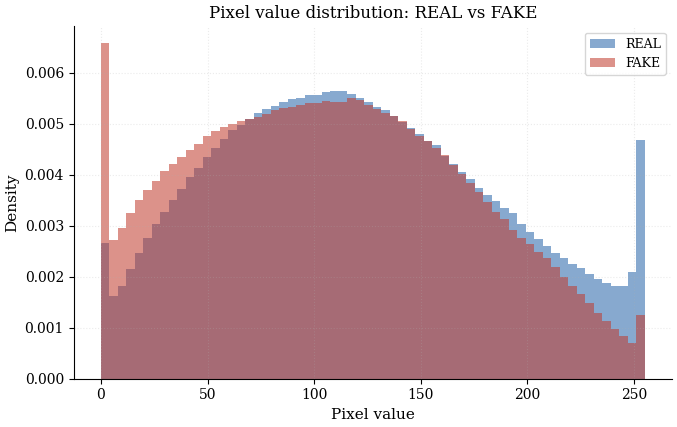

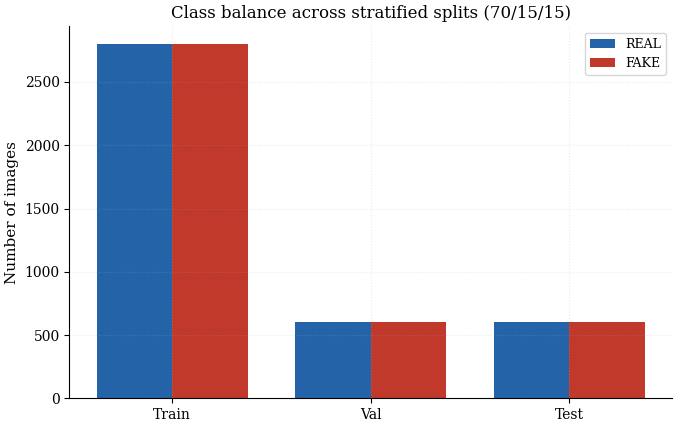

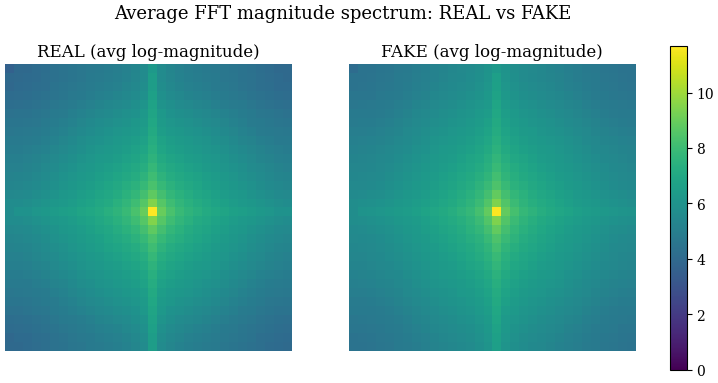

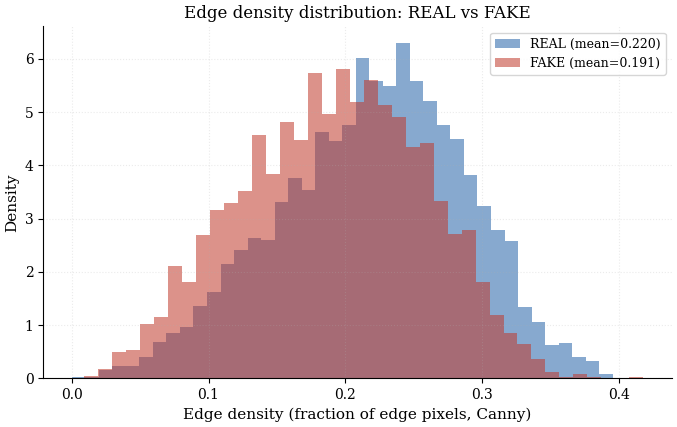

DONE. Saved into /content/drive/MyDrive/luanvan_thac_si/notebook01_artifacts
   True fig_eda_pixel_hist.png
   True fig_eda_class_count.png
   True fig_eda_fft_spectrum.png
   True fig_eda_edge_density.png


In [21]:
# ============================================================
# EDA CELL - Chapter 3 figures
# Saves DIRECTLY into the Drive folder 'notebook01_artifacts'
# (same place Cell 21 backs up all other figures), so they appear
# right next to fig_cm_vit_stage1.png etc.
#   fig_eda_pixel_hist.png, fig_eda_class_count.png,
#   fig_eda_fft_spectrum.png, fig_eda_edge_density.png
# ============================================================
import os, numpy as np, matplotlib.pyplot as plt, cv2
from datasets import load_dataset, concatenate_datasets
from sklearn.model_selection import train_test_split

# --- config (reuse CONFIG if present, else fallback) ---
try:
    DRIVE_BASE  = CONFIG.get('drive_backup', '/content/drive/MyDrive/luanvan_thac_si')
    HF_ID       = CONFIG['hf_dataset_id']
    SEED        = CONFIG.get('seed', 42)
    N_PER_CLASS = CONFIG.get('n_per_class', 4000)
except NameError:
    DRIVE_BASE  = '/content/drive/MyDrive/luanvan_thac_si'
    HF_ID       = 'dragonintelligence/CIFAKE-image-dataset'
    SEED, N_PER_CLASS = 42, 4000

from google.colab import drive
if not os.path.ismount('/content/drive'):
    drive.mount('/content/drive')

# IMPORTANT: save into the SAME Drive folder as the other backed-up figures
OUT = os.path.join(DRIVE_BASE, 'notebook01_artifacts')
os.makedirs(OUT, exist_ok=True)
FAKE_ID, REAL_ID = 0, 1
print('Saving EDA figures into:', OUT)

print('Loading CIFAKE ...')
raw = load_dataset(HF_ID)
ds  = concatenate_datasets([raw['train'], raw['test']])
lab_all = np.array(ds['label'])
rng = np.random.default_rng(SEED)
fi = rng.choice(np.where(lab_all == FAKE_ID)[0], N_PER_CLASS, replace=False)
ri = rng.choice(np.where(lab_all == REAL_ID)[0], N_PER_CLASS, replace=False)
sub = ds.select(np.concatenate([fi, ri]))
labels = np.array(sub['label'])
arr  = np.stack([np.asarray(im.convert('RGB')) for im in sub['image']])  # (N,32,32,3)
gray = arr.mean(3).astype(np.uint8)
real_m, fake_m = labels == REAL_ID, labels == FAKE_ID
print('Subset:', arr.shape, '| REAL', int(real_m.sum()), 'FAKE', int(fake_m.sum()))

# --- Fig 3.1: pixel value distribution ---
plt.figure(figsize=(7, 4.5))
plt.hist(arr[real_m].ravel(), bins=64, range=(0,255), density=True, alpha=0.55, label='REAL', color='#2563a8')
plt.hist(arr[fake_m].ravel(), bins=64, range=(0,255), density=True, alpha=0.55, label='FAKE', color='#c0392b')
plt.xlabel('Pixel value'); plt.ylabel('Density'); plt.title('Pixel value distribution: REAL vs FAKE')
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUT, 'fig_eda_pixel_hist.png'), dpi=150); plt.show()

# --- Fig 3.2: class balance across stratified splits ---
tr, te = train_test_split(np.arange(len(labels)), test_size=0.15, stratify=labels, random_state=SEED)
tr, va = train_test_split(tr, test_size=0.15/0.85, stratify=labels[tr], random_state=SEED)
splits = {'Train': labels[tr], 'Val': labels[va], 'Test': labels[te]}
xs = np.arange(len(splits)); w = 0.38
plt.figure(figsize=(7, 4.5))
plt.bar(xs-w/2, [int((v==REAL_ID).sum()) for v in splits.values()], w, label='REAL', color='#2563a8')
plt.bar(xs+w/2, [int((v==FAKE_ID).sum()) for v in splits.values()], w, label='FAKE', color='#c0392b')
plt.xticks(xs, list(splits.keys())); plt.ylabel('Number of images')
plt.title('Class balance across stratified splits (70/15/15)')
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUT, 'fig_eda_class_count.png'), dpi=150); plt.show()

# --- Fig 3.3: average FFT magnitude spectrum ---
def avg_spectrum(g):
    acc = np.zeros((32, 32), np.float64)
    for im in g:
        acc += np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(im.astype(np.float32)))))
    return acc / len(g)
sr, sf = avg_spectrum(gray[real_m]), avg_spectrum(gray[fake_m])
vmax = max(sr.max(), sf.max())
fig, ax = plt.subplots(1, 2, figsize=(9, 4.2))
for a, (s, t) in zip(ax, [(sr, 'REAL'), (sf, 'FAKE')]):
    im = a.imshow(s, cmap='viridis', vmin=0, vmax=vmax); a.set_title(f'{t} (avg log-magnitude)'); a.axis('off')
fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle('Average FFT magnitude spectrum: REAL vs FAKE')
plt.savefig(os.path.join(OUT, 'fig_eda_fft_spectrum.png'), dpi=150, bbox_inches='tight'); plt.show()

# --- Fig 3.4: edge density distribution (Canny) ---
def edge_density(g):
    return np.array([(cv2.Canny(im, 100, 200) > 0).mean() for im in g])
er, ef = edge_density(gray[real_m]), edge_density(gray[fake_m])
plt.figure(figsize=(7, 4.5))
plt.hist(er, bins=40, density=True, alpha=0.55, label=f'REAL (mean={er.mean():.3f})', color='#2563a8')
plt.hist(ef, bins=40, density=True, alpha=0.55, label=f'FAKE (mean={ef.mean():.3f})', color='#c0392b')
plt.xlabel('Edge density (fraction of edge pixels, Canny)'); plt.ylabel('Density')
plt.title('Edge density distribution: REAL vs FAKE')
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUT, 'fig_eda_edge_density.png'), dpi=150); plt.show()

print('DONE. Saved into', OUT)
for fn in ['fig_eda_pixel_hist.png','fig_eda_class_count.png','fig_eda_fft_spectrum.png','fig_eda_edge_density.png']:
    print('  ', os.path.exists(os.path.join(OUT, fn)), fn)


In [22]:
# ===== Section 5.1.1: per-epoch training table (val loss / accuracy / F1) =====
import os, glob, json, pandas as pd

log = None
try:                                    # 1) trainer still in memory (same session that trained)
    log = pd.DataFrame(trainer.state.log_history)
except NameError:                       # 2) read trainer_state.json from a checkpoint dir
    cands = []
    for base in [CONFIG.get('ckpt_dir', '/content/checkpoints'),
                 CONFIG.get('drive_backup', '/content/drive/MyDrive/luanvan_thac_si')]:
        cands += glob.glob(os.path.join(base, '**', 'trainer_state.json'), recursive=True)
    if cands:
        cands.sort(key=os.path.getmtime)
        log = pd.DataFrame(json.load(open(cands[-1]))['log_history'])
        print('Loaded log from:', cands[-1])

if log is None:
    print('No log found. Re-run the training cell in THIS session, then run this cell '
          '(the trainer object must still be in memory).')
else:
    ev = log[log['eval_loss'].notna()] if 'eval_loss' in log.columns else log
    cols = {'epoch':'Epoch', 'eval_loss':'Val loss', 'eval_accuracy':'Val accuracy',
            'eval_f1':'Val F1', 'eval_precision':'Val precision', 'eval_recall':'Val recall'}
    keep = [c for c in cols if c in ev.columns]
    tbl = ev[keep].rename(columns=cols)
    tbl['Epoch'] = tbl['Epoch'].round().astype(int)
    print(tbl.round(4).to_string(index=False))
    out = CONFIG.get('output_dir', '/content/outputs'); os.makedirs(out, exist_ok=True)
    tbl.to_csv(os.path.join(out, 'table_train_per_epoch.csv'), index=False)
    print('Saved:', os.path.join(out, 'table_train_per_epoch.csv'))


 Epoch  Val loss  Val accuracy  Val F1  Val precision  Val recall
     1    0.1906        0.9417  0.9403         0.9633      0.9183
     2    0.1311        0.9592  0.9597         0.9465      0.9733
     3    0.1206        0.9642  0.9647         0.9499      0.9800
     4    0.1203        0.9642  0.9637         0.9761      0.9517
     5    0.1095        0.9658  0.9659         0.9651      0.9667
Saved: /content/outputs/table_train_per_epoch.csv


# ===== MULTI-SEED EVALUATION (OPTIONAL -- run separately) =====

**This section is independent of `best_vit`.** The headline checkpoint above is
already saved. Run the cell below only to produce **Table 5.4** (multi-seed
mean +/- std, advisor requirement). It trains the *extra* seeds 1-4 and **reuses
the seed-42 result from Cell 9** for the seed-42 row, so the table's seed-42
value equals the headline exactly. Cost: 4 extra fine-tunes (~4x one training).
Skip it now and run later if you only need `best_vit`.


--- multi-seed: training seed 1 ---


Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  [seed 1] pre-train baseline: acc=58.50%  f1=58.64%


Epoch,Training Loss,Validation Loss,Model Preparation Time,Accuracy,F1,Precision,Recall
1,0.440200,0.192495,0.006200,0.945000,0.944538,0.952542,0.936667
2,0.146500,0.143528,0.006200,0.955000,0.954160,0.972318,0.936667
3,0.101400,0.122891,0.006200,0.964167,0.963774,0.974446,0.953333
4,0.079300,0.104104,0.006200,0.967500,0.967527,0.966722,0.968333
5,0.060900,0.102712,0.006200,0.967500,0.967742,0.960591,0.975000


  [seed 1] test: acc=96.58%  F1=96.57%  AUC-ROC=99.47%
--- multi-seed: training seed 2 ---


...

  [seed 3] test: acc=95.67%  F1=95.72%  AUC-ROC=99.24%
--- multi-seed: training seed 4 ---


Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  [seed 4] pre-train baseline: acc=46.25%  f1=55.67%


Epoch,Training Loss,Validation Loss,Model Preparation Time,Accuracy,F1,Precision,Recall
1,0.431600,0.178392,0.002800,0.954167,0.954658,0.944535,0.965000
2,0.151500,0.132702,0.002800,0.958333,0.959016,0.943548,0.975000
3,0.097000,0.110500,0.002800,0.970000,0.970000,0.970000,0.970000
4,0.075000,0.105072,0.002800,0.969167,0.969089,0.971524,0.966667
5,0.059000,0.106951,0.002800,0.968333,0.968280,0.969900,0.966667


  [seed 4] test: acc=95.75%  F1=95.75%  AUC-ROC=99.32%

 MULTI-SEED SUMMARY  (positive class = FAKE)
                 mean    std     min     max
Accuracy (%)   95.950  0.366  95.667  96.583
F1-Score (%)   95.954  0.355  95.724  96.575
Precision (%)  95.883  0.890  94.481  96.817
Recall (%)     96.033  0.691  95.167  97.000
Mean IoU (%)   92.217  0.679  91.692  93.392
AUC-ROC (%)    99.311  0.100  99.220  99.472
PR-AUC (%)     99.230  0.173  98.980  99.448

Per-seed:
      Accuracy (%)  F1-Score (%)  AUC-ROC (%)
seed                                         
42           95.83         95.81        99.30
1            96.58         96.57        99.47
2            95.92         95.92        99.22
3            95.67         95.72        99.24
4            95.75         95.75        99.32
[OK] Saved /content/outputs/table_multiseed_vit_per_seed.csv and /content/outputs/table_multiseed_vit_per_seed.md
[OK] Saved /content/outputs/table_multiseed_vit_summary.csv and /content/outputs/table_multi

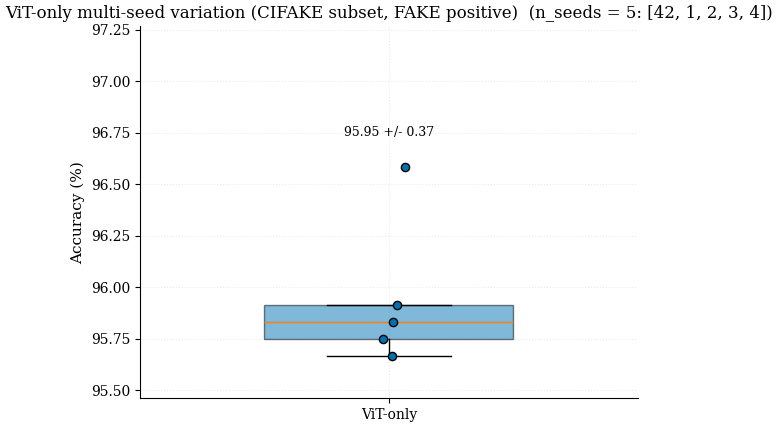


-> Headline for Section 5.1.5: ViT-only = 95.95 +/- 0.37% (n=5 seeds). seed 42 row = 95.83% (matches Cell 9 headline).


In [23]:
# ============================================================
# CELL 15: MULTI-SEED TABLE (Section 5.1.5, Table 5.4)
# ============================================================
# Advisor requirement: 3-5 seeds, report mean +/- std. Uses the SAME
# train_vit() so seed 42 here == the headline in Cell 9 (reused, not
# retrained). Only seeds 1-4 are trained now.

import gc
seeds = CONFIG['multiseed_seeds']             # [42, 1, 2, 3, 4]
ms_metrics = {CONFIG['seed']: MS_SEED42_METRICS}   # reuse seed-42 (no retrain)

for s in seeds:
    if s == CONFIG['seed']:
        continue
    print(f"--- multi-seed: training seed {s} ---")
    r = train_vit(s, save_dir=None, verbose=True)
    ms_metrics[s] = r['metrics']
    del r
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Aggregate -> mean / std / min / max
runs_list = [ms_metrics[s] for s in seeds]
ms_summary = aggregate_multiseed(runs_list, seeds=[f'seed {s}' for s in seeds])

print("\n" + "=" * 60)
print(" MULTI-SEED SUMMARY  (positive class = FAKE)")
print("=" * 60)
print(ms_summary.round(3).to_string())

# Per-seed table (for the thesis Bang 5.4) + save
import pandas as pd
per_seed = pd.DataFrame(
    {s: {k: ms_metrics[s][k] for k in
         ['Accuracy (%)', 'F1-Score (%)', 'AUC-ROC (%)']}
     for s in seeds}
).T
per_seed.index.name = 'seed'
print("\nPer-seed:")
print(per_seed.round(2).to_string())

save_results_csv(per_seed.round(3),
                 os.path.join(CONFIG['output_dir'], 'table_multiseed_vit_per_seed.csv'))
save_results_csv(ms_summary.round(3),
                 os.path.join(CONFIG['output_dir'], 'table_multiseed_vit_summary.csv'))

# Box + strip plot annotated with mean +/- std
runs_for_plot = {'ViT-only': [ms_metrics[s]['Accuracy (%)'] for s in seeds]}
plot_multiseed(
    seeds, runs_for_plot, metric_name='Accuracy (%)',
    title='ViT-only multi-seed variation (CIFAKE subset, FAKE positive)',
    save_path=os.path.join(CONFIG['output_dir'], 'fig_multiseed_vit.png'),
)

acc_mean = float(per_seed['Accuracy (%)'].mean())
acc_std  = float(per_seed['Accuracy (%)'].std(ddof=1))
print(f"\n-> Headline for Section 5.1.5: ViT-only = {acc_mean:.2f} +/- {acc_std:.2f}% "
      f"(n={len(seeds)} seeds). seed 42 row = {ms_metrics[CONFIG['seed']]['Accuracy (%)']:.2f}% "
      f"(matches Cell 9 headline).")


In [24]:
# ============================================================
# CELL 16: CANONICAL SUMMARY  (copy these into the thesis)
# ============================================================
# Single place that prints every number the thesis Chapter 5 needs, so
# Section 5.1.2 / 5.1.3 / 5.1.5 / Table 5.10 stay consistent with ONE run.

print("=" * 64)
print(" NUMBERS TO PASTE INTO THE THESIS  (positive class = FAKE)")
print("=" * 64)
print(f"[5.1.2 headline / Table 5.10 B1]  ViT-only:")
print(f"   acc={HEADLINE_METRICS['Accuracy (%)']:.2f}%  "
      f"F1={HEADLINE_METRICS['F1-Score (%)']:.2f}%  "
      f"AUC={HEADLINE_METRICS.get('AUC-ROC (%)', float('nan')):.2f}%  "
      f"PR-AUC={HEADLINE_METRICS.get('PR-AUC (%)', float('nan')):.2f}%")
print()
print("[5.1.3 five inference modes]")
for nm, mm in [('Mode 0 leaked (INVALID)', m_leak), ('Mode 1 ViT-only', m_vit),
               ('Mode 2 EBP-only', m_ebp), ('Mode 3 gated', m_gated),
               ('Mode 4 LogReg fusion', m_fusion)]:
    print(f"   {nm:26s}: acc={mm['Accuracy (%)']:.2f}%  F1={mm['F1-Score (%)']:.2f}%")
print()
print("[5.1.4 confusion matrix, ViT-only]")
n_rf = int(((vit_true == REAL_ID) & (vit_pred == FAKE_ID)).sum())
n_fr = int(((vit_true == FAKE_ID) & (vit_pred == REAL_ID)).sum())
print(f"   Real->Fake = {n_rf},  Fake->Real = {n_fr},  total errors = {n_rf+n_fr}/{len(vit_true)}")
print()
print("[5.1.5 multi-seed]  -> run the multi-seed section above; it prints mean +/- std.")
print("[5.1.6 EBP diagnostic]  EBP-only AUC={:.1f}%  (>>chance only if >55%)".format(
    m_ebp.get('AUC-ROC (%)', float('nan'))))
print("=" * 64)
print("best_vit saved to:", best_vit_dir)
print("Re-run Notebooks 02/03/04 against THIS best_vit before updating their results.")


 NUMBERS TO PASTE INTO THE THESIS  (positive class = FAKE)
[5.1.2 headline / Table 5.10 B1]  ViT-only:
   acc=95.83%  F1=95.81%  AUC=99.30%  PR-AUC=99.24%

[5.1.3 five inference modes]
   Mode 0 leaked (INVALID)   : acc=97.42%  F1=97.40%
   Mode 1 ViT-only           : acc=95.83%  F1=95.81%
   Mode 2 EBP-only           : acc=52.00%  F1=49.47%
   Mode 3 gated              : acc=95.42%  F1=95.40%
   Mode 4 LogReg fusion      : acc=95.83%  F1=95.81%

[5.1.4 confusion matrix, ViT-only]
   Real->Fake = 21,  Fake->Real = 29,  total errors = 50/1200

[5.1.5 multi-seed]  -> run the multi-seed section above; it prints mean +/- std.
[5.1.6 EBP diagnostic]  EBP-only AUC=51.7%  (>>chance only if >55%)
best_vit saved to: /content/checkpoints/best_vit
Re-run Notebooks 02/03/04 against THIS best_vit before updating their results.
